In [1]:
## Code to read in the final models and assess variable contributions etc. ##

# Load in the required packages 

# Read in the packages to use
import numpy as np
import pandas as pd
import math
import datetime
import os
import pathlib
import matplotlib.pyplot as plt
import earthpy as et
import pickle
import random    

from sklearn.model_selection import GridSearchCV                      #for cross validation
from sklearn.feature_selection import RFE                             #for selecting features for the linear reg
from sklearn.model_selection import cross_val_score                   #for cross validation
from sklearn.model_selection import KFold                            
from sklearn.model_selection import GridSearchCV 
from sklearn.preprocessing import StandardScaler                      #for normalising the data
from sklearn.metrics import r2_score                                  #metrics for assessing model
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import GroupShuffleSplit
from sklearn.model_selection import StratifiedShuffleSplit
import statsmodels.api as sm                                          #stats models to get linear reg p-values
from statsmodels.tools.eval_measures import rmse                      #calc rmse from stats models
import itertools                                                      #for calculating possible combinations of variables
from sklearn.preprocessing import PolynomialFeatures                  #for polynomial regression
from sklearn.pipeline import make_pipeline             
from xgboost import XGBRegressor

import pvlib
import pytz

# load in the training data:
parent_folder = r"C:/Users/Sarah/Documents/Python_Scripts/DDL/Sensor_Network/Heat_model_Durham_Raleigh/"
train_data_path = os.path.join(parent_folder,"data/joined_data/ERA5_everyday_merged.csv")
data = pd.read_csv(train_data_path)

# sensor info - landcover type and shading scenario
sensor_info_path= r"C:\Users\Sarah\Documents\Python_Scripts\DDL\Sensor_Network\Heat_model_Durham_Raleigh\data\Installed Sensors_0.csv"
sensor_info = pd.read_csv(sensor_info_path)
landcover_shading_info = sensor_info.rename(columns = {'Sensor Serial Number':'Sensor_ID'})[['Sensor_ID','Landcover Type','Shade Type']]
data = data.merge(landcover_shading_info, on = 'Sensor_ID', how ='left')

# add in variable -- SVFs from the fisheye photos
fisheye_data_path = r"C:\Users\Sarah\Documents\Python_Scripts\DDL\Sensor_Network\Heat_model_Durham_Raleigh\data\Fisheye_Data\skyview_factors.csv"
fisheye_data = pd.read_csv(fisheye_data_path)
data = data.merge(fisheye_data[['Sensor_ID','SVF']], on = 'Sensor_ID', how = 'left')


### ----- Pre-clean -------
# fill 0 to categorical vars
# data.fillna(data.mean(),inplace = True)
# Create Cyclical Features for custom hour
#data.dropna(subset = ["Temperature"],inplace = True)
# Convert hours and minutes to total minutes since midnight
data['Hour'] = pd.to_datetime(data['Hour'], format='%H' )
data['Hour'] = data['Hour'].dt.hour
data['Total_Minutes'] = data['Hour'] * 60

# Create cyclical features using sine and cosine transformations
data['sin_time'] = np.sin(2 * np.pi * data['Total_Minutes'] / 1440)  # 1440 = total minutes in a day
data['cos_time'] = np.cos(2 * np.pi * data['Total_Minutes'] / 1440)

# get the zenith angle 
# convert to UTC for use in pvlib 
data['edt_datetime'] = pd.to_datetime(data['edt_datetime']).dt.tz_localize('US/Eastern')
data['utc_datetime'] = data['edt_datetime'].dt.tz_convert('UTC')
durham_lat = 35.99260
durham_lon = -78.89892
# calc solar positions
solpos = pvlib.solarposition.get_solarposition(
    time=data['utc_datetime'],
    latitude=durham_lat,
    longitude=durham_lon
)

# Add zenith angle to data 
data['zenith_angle'] = solpos['zenith'].values

# add in a temperature anomomly quantification to try as target variable (remove diurnal cycle)
data['temp_anom'] = data['Temperature'] - data['temperature_2m'] 
data['rh_anom'] = data['Relative_Humidity'] - data['relative_humidity_2m'] 


# add in the diurnal range -  this is so that the AT measurement standard error confidence intervals can be added into the main dataframe
# first find the mean daily hourly temps between the sensors
data_hour_means = data[['Temperature','Date','Hour']].groupby(['Date','Hour']).mean().reset_index()
# then group to find the min max
daily_max = data_hour_means[['Temperature','Date']].groupby('Date').max().reset_index().rename(columns ={'Temperature':'Max_Temp'})
daily_min = data_hour_means[['Temperature','Date']].groupby('Date').min().reset_index().rename(columns ={'Temperature':'Min_Temp'})
# substract min max to get the range
diurnal_ranges = daily_max.merge(daily_min, on = 'Date', how = 'left')
diurnal_ranges['Diurnal_Range'] = diurnal_ranges['Max_Temp']-diurnal_ranges['Min_Temp']
# add the diurnal range into the main data 
data = data.merge(diurnal_ranges[['Date','Diurnal_Range']], on = 'Date', how ='left')


### --- Define Model specs -----
# define Y and X
group_name = "Sensor_ID"
Y_name = "temp_anom"

# static variables first, then dynamic
X_names_day =[ 'NDBI_2024SummerMosaic',
          'NDVI_2024SummerMosaic', 'ESA_50',  
         'nearest_motorway_thru_primary_dist','NDMI', 'Tree_DSM_SVF','Albedo_2024SummerMosaic',
         'zenith_angle',#'cos_time', 
              'surface_net_thermal_radiation_hourly','surface_solar_radiation_downwards_hourly',
        'surface_thermal_radiation_downwards_hourly',  'surface_solar_radiation_downwards_accumulation',
        'u_component_of_wind_10m',  'v_component_of_wind_10m', 'windspeed_10m', 
        'relative_humidity_2m', 'temperature_2m', 'total_precipitation_hourly',
           ]

X_names_day.append(group_name)
X_names_day.append('Hour') # save hour so can split by this later for analysis

X_names_night =['NDBI_2024SummerMosaic', 'NDVI_2024SummerMosaic', 'ESA_50', 'nearest_motorway_thru_primary_dist',  'zenith_angle',#'cos_time',  
     'surface_net_thermal_radiation_hourly', 'surface_thermal_radiation_downwards_hourly', 'Tree_DSM_SVF', 
     'surface_solar_radiation_downwards_accumulation', 'u_component_of_wind_10m', 'v_component_of_wind_10m',
     'windspeed_10m', 'relative_humidity_2m', 
     'temperature_2m', 'total_precipitation_hourly']

X_names_night.append(group_name)
X_names_night.append('Hour') # save hour so can split by this later for analysis


# determine the train and test based on landcover/ shading scenario, uncomment/ comment to get scenario to test
#to_split_on = 'Landcover Type'
#to_train_on = 'vegetation'
#to_train_on = 'impervious'

to_split_on = 'Shade Type'
#to_train_on = 'shaded'
to_train_on = 'non-shaded'

train_sensor_ids = list(set(data[data[to_split_on] == to_train_on].Sensor_ID))
test_sensor_ids  = list(set(data[data[to_split_on] != to_train_on].Sensor_ID))

# modelling for incoming sol rad (daytime)
data_day = data[data['surface_solar_radiation_downwards_hourly'] > 1].copy().reset_index(drop = True)

# Apply split to full dataset
train_mask_day = data_day['Sensor_ID'].isin(train_sensor_ids)
test_mask_day  = data_day['Sensor_ID'].isin(test_sensor_ids)

y_day = data_day[Y_name].copy()
X_day = data_day[X_names_day].copy()

X_train_day, X_test_day = X_day[train_mask_day].copy(), X_day[test_mask_day].copy()
y_train_day, y_test_day = y_day[train_mask_day].copy(), y_day[test_mask_day].copy()

# copy datasets before removing hour/id for later analysis
train_day_w_hour = X_train_day.copy()
train_day_w_hour['Temperature'] = y_train_day
test_day_w_hour = X_test_day.copy()
test_day_w_hour['Temperature'] = y_test_day

# Drop ID/hour cols before modeling
X_train_day.drop(columns=[group_name, 'Hour'], inplace=True)
X_test_day.drop(columns=[group_name, 'Hour'], inplace=True)

#create normalised datasets
scaler = StandardScaler()
X_train_norm_day = pd.DataFrame(scaler.fit_transform(X_train_day.values), columns = X_train_day.columns) #fit and transform
X_test_norm_day = pd.DataFrame(scaler.transform(X_test_day.values), columns = X_test_day.columns) #transform only


# modelling for no incoming sol rad (nighttime)
data_night = data[data['surface_solar_radiation_downwards_hourly'] < 1].copy().reset_index(drop = True)
# Apply split to full dataset
train_mask_night = data_night['Sensor_ID'].isin(train_sensor_ids)
test_mask_night  = data_night['Sensor_ID'].isin(test_sensor_ids)

y_night = data_night[Y_name].copy()
X_night = data_night[X_names_night].copy()

X_train_night, X_test_night = X_night[train_mask_night].copy(), X_night[test_mask_night].copy()
y_train_night, y_test_night = y_night[train_mask_night].copy(), y_night[test_mask_night].copy()

# copy datasets before removing hour/id for later analysis
train_night_w_hour = X_train_night.copy()
train_night_w_hour['Temperature'] = y_train_night
test_night_w_hour = X_test_night.copy()
test_night_w_hour['Temperature'] = y_test_night

# Drop ID/hour cols before modeling
X_train_night.drop(columns=[group_name, 'Hour'], inplace=True)
X_test_night.drop(columns=[group_name, 'Hour'], inplace=True)

#create normalised datasets
scaler = StandardScaler()
X_train_norm_night = pd.DataFrame(scaler.fit_transform(X_train_night.values), columns = X_train_night.columns) #fit and transform
X_test_norm_night = pd.DataFrame(scaler.transform(X_test_night.values), columns = X_test_night.columns) #transform only

# function for getting the prediction interval
# y0 is the predicted value for an observation, y is actual values, y_pred is predicted values
def calc_pred_error(y, y_pred):                                       
    mse = mean_squared_error(y, y_pred) # calculate the mean squared error
    n = len(y_pred)
    mean_pred = np.mean(y_pred)
    y_pred_interval = []
    for y0 in y_pred:
        stderr = mse*(1+1/float(n)+(y0 - mean_pred)**2/np.sum((y_pred - mean_pred)**2))
        pred_interval = np.sqrt(stderr)
        y_pred_interval.append(pred_interval)
    return y_pred_interval


print(f"\nTrain sensors: {len(train_sensor_ids)}  Test sensors: {len(test_sensor_ids)}")

## daytime model 
day_xgb_model = XGBRegressor(objective='reg:squarederror', random_state=42,
                             n_estimators =883,max_depth = 8, learning_rate = 0.059,
                             subsample = 0.6,colsample_bytree = 0.61, min_child_weight =17,
                             gamma =  0.001,reg_alpha =0.0001 ,reg_lambda=80) 

day_xgb_model.fit(X_train_norm_day, y_train_day)

y_train_pred_day = day_xgb_model.predict(X_train_norm_day)
y_test_pred_day = day_xgb_model.predict(X_test_norm_day)

# Add city mean back to anomaly predictions
y_test_pred_full_day = y_test_pred_day + data_day[test_mask_day][ "temperature_2m"].values
y_train_pred_full_day = y_train_pred_day + data_day[train_mask_day][ "temperature_2m"].values
# Also get the true "full" temperatures
y_test_full_day = y_test_day + data_day[test_mask_day]["temperature_2m"].values
y_train_full_day = y_train_day + data_day[train_mask_day]["temperature_2m"].values


## nighttime model 
night_xgb_model = XGBRegressor(objective='reg:squarederror', random_state=42,
                             n_estimators =700,max_depth = 7, learning_rate = 0.2,
                             subsample = 0.9,colsample_bytree = 0.4, min_child_weight =26,
                             gamma =  0.014,reg_alpha =0.002 ,reg_lambda=57) 

night_xgb_model.fit(X_train_norm_night, y_train_night)

y_train_pred_night = night_xgb_model.predict(X_train_norm_night)
y_test_pred_night = night_xgb_model.predict(X_test_norm_night)

# Add city mean back to anomaly predictions
y_test_pred_full_night = y_test_pred_night + data_night[test_mask_night][ "temperature_2m"].values
y_train_pred_full_night = y_train_pred_night + data_night[train_mask_night][ "temperature_2m"].values
# Also get the true "full" temperatures
y_test_full_night = y_test_night + data_night[test_mask_night]["temperature_2m"].values
y_train_full_night = y_train_night + data_night[train_mask_night]["temperature_2m"].values

## Predictions for the entire 24hrs
y_test_pred_24hrs = np.concatenate([y_test_pred_full_day , y_test_pred_full_night])
y_train_pred_24hrs = np.concatenate([y_train_pred_full_day,y_train_pred_full_night])
y_test_24hrs = np.concatenate([y_test_full_day ,y_test_full_night])
y_train_24hrs = np.concatenate([y_train_full_day , y_train_full_night])


# add the data back into the dataframes 
data_night.loc[test_mask_night, 'Predicted_Temperature'] = y_test_pred_full_night
data_night.loc[train_mask_night, 'Predicted_Temperature'] = y_train_pred_full_night
data_day.loc[test_mask_day, 'Predicted_Temperature'] = y_test_pred_full_day
data_day.loc[train_mask_day, 'Predicted_Temperature'] = y_train_pred_full_day
data_full_24hrs = pd.concat([data_day, data_night])

C:\Users\Sarah\anaconda3\envs\durham_ml_analysis_env\Lib\site-packages\earthpy\__init__.py:7: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_string



Train sensors: 19  Test sensors: 20


Training Metrics-- RMSE: 0.47734786085055053 R-square: 0.9900473267758435 MAE: 0.3326446505226296 MBE: 0.0007851207999269737 MPE (%): 0.04530388846994511
Test Metrics-- RMSE: 1.4294063917826105 R-square: 0.8852301034091141 MAE: 1.1102322141511494 MBE: 0.7800243761798319 MPE (%): 2.800910149567314


Text(0.05, 0.85, 'RMSE= 1.43°C')

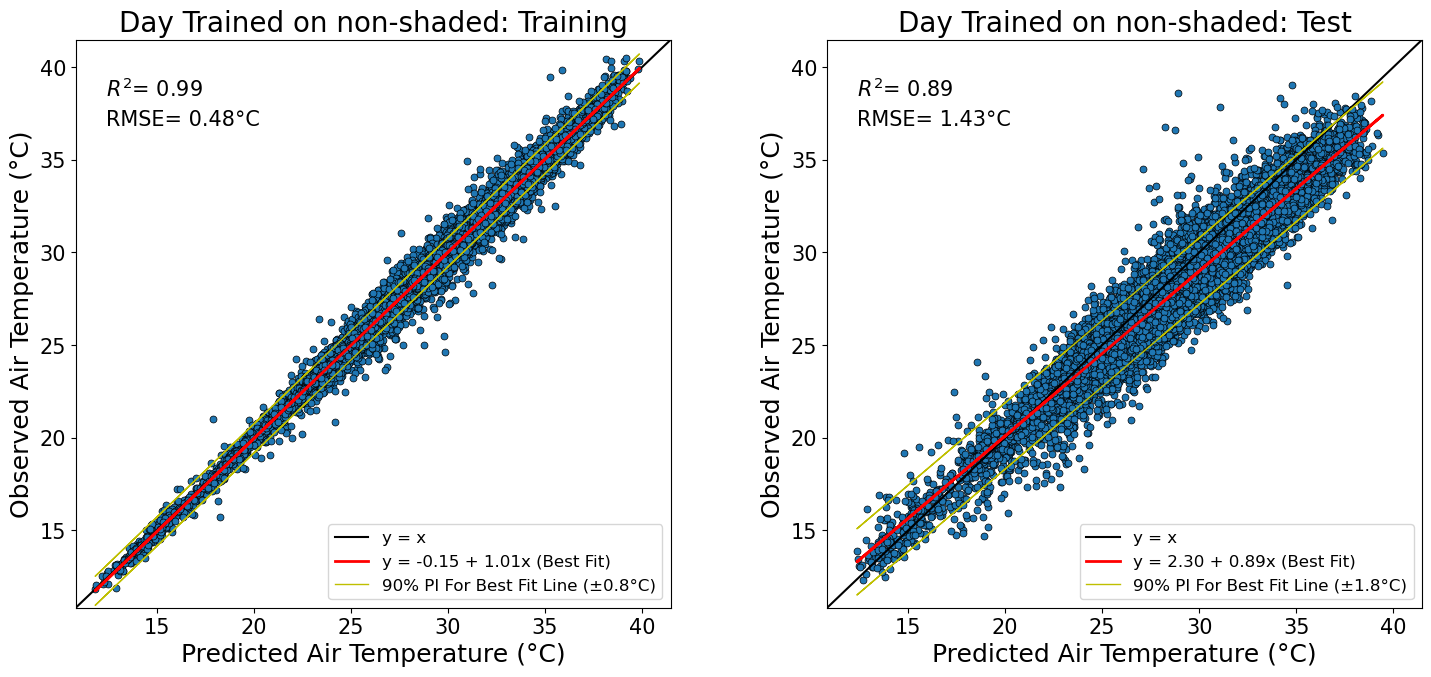

In [2]:
model_name = f'Day Trained on {to_train_on}:'


y_test_pred_full = y_test_pred_full_day
y_train_pred_full = y_train_pred_full_day
y_test_full = y_test_full_day
y_train_full = y_train_full_day

######################################################
###### Performance Metrics for the training set ######
######################################################
#rmse
train_rmse = np.sqrt(mean_squared_error(y_train_full, y_train_pred_full))
#r-square~
train_r2 = r2_score(y_train_full, y_train_pred_full)
#mae
train_mae = mean_absolute_error(y_train_full, y_train_pred_full)
#mbe
train_mbe = np.mean(y_train_pred_full - y_train_full)
#mean percentage error (mpe)
train_mpe = np.mean((y_train_pred_full - y_train_full) / y_train_full) * 100

print(
    'Training Metrics--',
    'RMSE:', train_rmse,
    'R-square:', train_r2,
    'MAE:', train_mae,
    'MBE:', train_mbe,
    'MPE (%):', train_mpe
)

#################################################
###### Performance Metrics for the test set #####
#################################################
#rmse
test_rmse = np.sqrt(mean_squared_error(y_test_full, y_test_pred_full))
#r-square
test_r2 = r2_score(y_test_full, y_test_pred_full)
#mae
test_mae = mean_absolute_error(y_test_full, y_test_pred_full)
#mbe
test_mbe = np.mean(y_test_pred_full - y_test_full)
#mean percentage error (mpe)
test_mpe = np.mean((y_test_pred_full - y_test_full) / y_test_full) * 100

print(
    'Test Metrics--',
    'RMSE:', test_rmse,
    'R-square:', test_r2,
    'MAE:', test_mae,
    'MBE:', test_mbe,
    'MPE (%):', test_mpe
)

# PLOTS: obvs vs predictions

#plt.rc('font', size=15)          # controls default text sizes
plt.rc('axes', titlesize=20)     # fontsize of the axes title
plt.rc('axes', labelsize=18)    # fontsize of the x and y labels
plt.rc('xtick', labelsize=15)    # fontsize of the tick labels
plt.rc('ytick', labelsize=15)    # fontsize of the tick labels
plt.rc('legend', fontsize=12)    # legend fontsize
plt.rc('figure', titlesize=20)  # fontsize of the figure title

# set plot labels
xlab = 'Predicted Air Temperature (\u00b0C)'
ylab = 'Observed Air Temperature (\u00b0C)'

# set the plot titles
train_title = '{} Training'.format(model_name)
test_title = '{} Test'.format(model_name)
    
# PLOTS: predictions vs obvs with line of best fit 

fig, axes = plt.subplots(1,2, figsize = (16, 8))
fig.tight_layout(pad=7.0)
# training data
axes[0].scatter( y_train_pred_full, y_train_full, s = 25, edgecolors='k', linewidths=0.5)
axes[0].set(title = train_title, 
         xlabel = xlab, ylabel = ylab)

axesmin = min(min(y_train_full), min(y_train_pred_full),min(y_test_full), min(y_test_pred_full)) - 1
axesmax = max(max(y_train_full), max(y_train_pred_full), max(y_test_full), max(y_test_pred_full)) + 1

axes[0].set_xlim([axesmin, axesmax])
axes[0].set_ylim([axesmin, axesmax])
# x = y line
axes[0].plot([axesmin, axesmax],[axesmin, axesmax], color = 'k', label = 'y = x')
# line of best fit
#p, V = np.polyfit(y_train_pred, y_train, 1, cov = True)
#a, b = p[0], p[1]

#get the intercept/ slope of best fit line and prediction interval
sm_model = sm.OLS(y_train_full, sm.add_constant(y_train_pred_full)).fit()
b = sm_model.params.iloc[0]
a = sm_model.params.iloc[1]
sm_pred = sm_model.get_prediction(sm.add_constant(y_train_pred_full))\
                  .summary_frame(alpha=0.1)

pred_interval_lower = sm_pred.obs_ci_lower.values
pred_interval_upper = sm_pred.obs_ci_upper.values
mean_PI = ((pred_interval_upper - pred_interval_lower)/2).mean()

axes[0].plot(y_train_pred_full, a*y_train_pred_full+b, color='r', linestyle='-', linewidth=2, label = 'y = ' + '{:.2f}'.format(b)+ 
             ' + {:.2f}'.format(a) + 'x (Best Fit)')

#axes[0].plot(y_train_pred, a*y_train_pred+b + np.std(a*y_train_pred+b), color='r', linestyle='--', 
#             linewidth=1, label = 'Fit std')
#axes[0].plot(y_train_pred, a*y_train_pred+b - np.std(a*y_train_pred+b), color='r', linestyle='--', linewidth=1)


axes[0].plot(y_train_pred_full , pred_interval_lower, color = 'y', linestyle='-', linewidth=1
             ,label = '90% PI For Best Fit Line ({}{:.1f}{})'.format(u'\u00B1',mean_PI,'\u00b0C'))
axes[0].plot(y_train_pred_full , pred_interval_upper, color = 'y', linestyle='-', linewidth=1)


#text labels
axes[0].text(0.05, 0.9, '$R^2$= {}'.format(round(train_r2, 2)), fontsize=15, transform=axes[0].transAxes)
axes[0].text(0.05, 0.85, 'RMSE= {}\u00b0C'.format(round(train_rmse, 2)), fontsize=15, transform=axes[0].transAxes)
#axes[0].text(0.05, 0.02, 'y = ' + '{:.2f}'.format(b)+ 
#             ' + {:.2f}'.format(a) + 'x ', 
#             size=15,transform=axes[0].transAxes, color = 'r')

axes[0].legend(loc = 4)
# test data
axes[1].scatter(y_test_pred_full, y_test_full, s = 25, edgecolors='k', linewidths=0.5)
axes[1].set(title = test_title, 
         xlabel = xlab, ylabel = ylab)

axesmin = min(min(y_train_full), min(y_train_pred_full),min(y_test_full), min(y_test_pred_full)) - 1
axesmax = max(max(y_train_full), max(y_train_pred_full), max(y_test_full), max(y_test_pred_full)) + 1

axes[1].set_xlim([axesmin, axesmax])
axes[1].set_ylim([axesmin, axesmax])
axes[1].plot([axesmin, axesmax],[axesmin, axesmax], color = 'k', label = 'y = x')
#get the intercept/ slope of best fit line and prediction interval
sm_model = sm.OLS(y_test_full, sm.add_constant(y_test_pred_full)).fit()
b = sm_model.params.iloc[0]
a = sm_model.params.iloc[1]
sm_pred = sm_model.get_prediction(sm.add_constant(y_test_pred_full))\
                  .summary_frame(alpha=0.1)

pred_interval_lower = sm_pred.obs_ci_lower.values
pred_interval_upper = sm_pred.obs_ci_upper.values
mean_PI = ((pred_interval_upper - pred_interval_lower)/2).mean()
pred_interval = calc_pred_error(y_test_full, y_test_pred_full)

#axes[1].scatter(y_test_pred, y_test_pred+pred_interval, s = 25, color = 'orange' , edgecolors='k', linewidths=0.5)

axes[1].plot(y_test_pred_full, a*y_test_pred_full +b, color='r', linestyle='-', linewidth=2, label = 'y = ' + '{:.2f}'.format(b)+ 
             ' + {:.2f}'.format(a) + 'x (Best Fit)')

axes[1].plot(y_test_pred_full , pred_interval_lower, color = 'y', linestyle='-', linewidth=1
            ,label = '90% PI For Best Fit Line ({}{:.1f}{})'.format(u'\u00B1',mean_PI,'\u00b0C'))
axes[1].plot(y_test_pred_full , pred_interval_upper, color = 'y', linestyle='-', linewidth=1) 


axes[1].legend(loc = 4)

axes[1].text(0.05, 0.9, '$R^2$= {}'.format(round(test_r2, 2)), fontsize=15, transform=axes[1].transAxes)
axes[1].text(0.05, 0.85, 'RMSE= {}\u00b0C'.format(round(test_rmse, 2)), fontsize=15, transform=axes[1].transAxes)

#add letters for figs
#axes[0].text(-0.08, 1, 'a', fontsize=35, transform=axes[0].transAxes)
#axes[1].text(-0.08, 1, 'b', fontsize=35, transform=axes[1].transAxes)


Training Metrics-- RMSE: 0.15657929216195443 R-square: 0.9974374553019768 MAE: 0.11475805478502056
Test Metrics-- RMSE: 0.8435404842690563 R-square: 0.9192080304853171 MAE: 0.6038961264077061


Text(-0.08, 1, 'b')

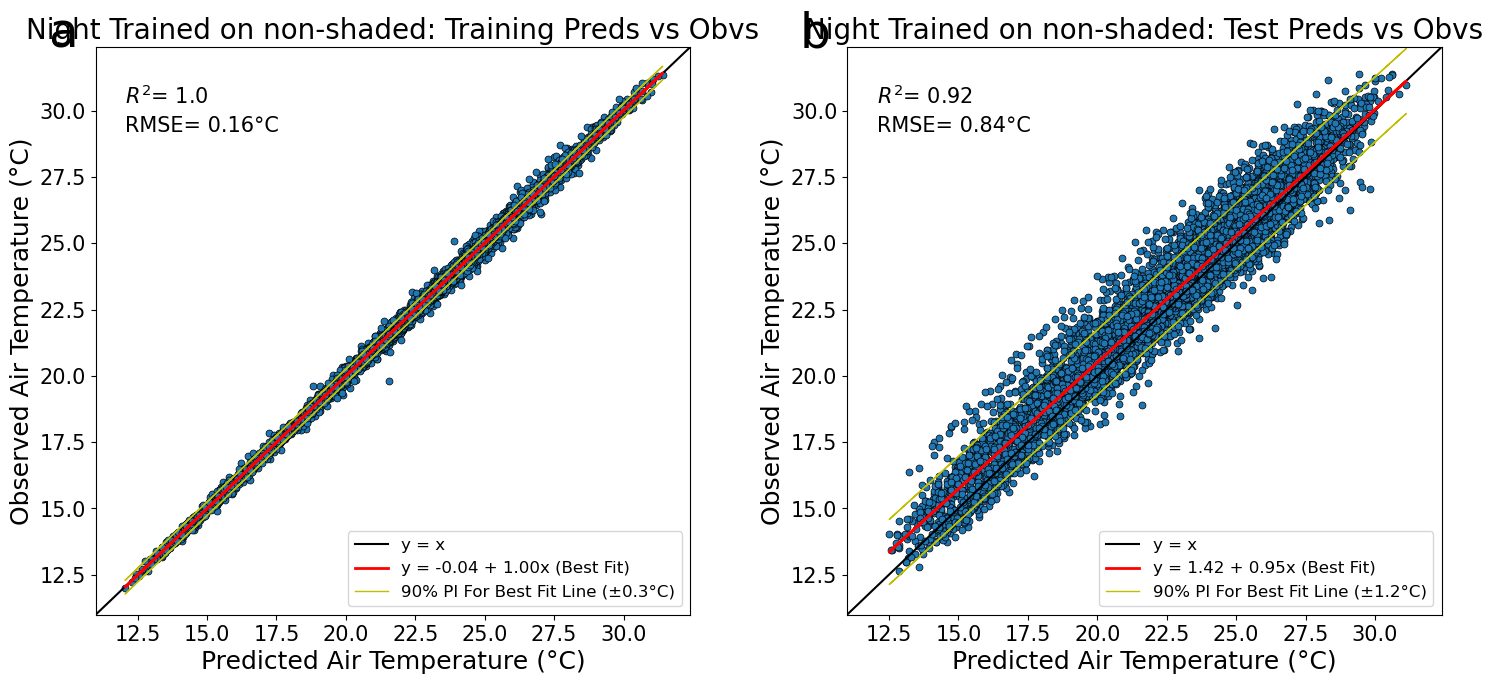

In [3]:
model_name = f'Night Trained on {to_train_on}:'
y_test_pred_full = y_test_pred_full_night
y_train_pred_full = y_train_pred_full_night
y_test_full = y_test_full_night
y_train_full = y_train_full_night

######################################################
###### Performance Metrics for the training set ######
######################################################
#rmse
train_rmse = np.sqrt(mean_squared_error(y_train_full, y_train_pred_full))
#r-square~
train_r2 = r2_score(y_train_full, y_train_pred_full)
#mae
train_mae = mean_absolute_error(y_train_full, y_train_pred_full)
print('Training Metrics--', 'RMSE:', train_rmse, 'R-square:', train_r2, 'MAE:', train_mae)

#################################################
###### Performance Metrics for the test set #####
#################################################
#rmse
test_rmse = np.sqrt(mean_squared_error(y_test_full, y_test_pred_full))
#r-square
test_r2 = r2_score(y_test_full, y_test_pred_full)
#mae
test_mae = mean_absolute_error(y_test_full, y_test_pred_full)
print('Test Metrics--', 'RMSE:', test_rmse, 'R-square:', test_r2, 'MAE:', test_mae)

# PLOTS: obvs vs predictions

#plt.rc('font', size=15)          # controls default text sizes
plt.rc('axes', titlesize=20)     # fontsize of the axes title
plt.rc('axes', labelsize=18)    # fontsize of the x and y labels
plt.rc('xtick', labelsize=15)    # fontsize of the tick labels
plt.rc('ytick', labelsize=15)    # fontsize of the tick labels
plt.rc('legend', fontsize=12)    # legend fontsize
plt.rc('figure', titlesize=20)  # fontsize of the figure title

# set plot labels
xlab = 'Predicted Air Temperature (\u00b0C)'
ylab = 'Observed Air Temperature (\u00b0C)'

# set the plot titles
train_title = '{} Training Preds vs Obvs'.format(model_name)
test_title = '{} Test Preds vs Obvs'.format(model_name)
    
# PLOTS: predictions vs obvs with line of best fit 

fig, axes = plt.subplots(1,2, figsize = (16, 8))
fig.tight_layout(pad=7.0)
# training data
axes[0].scatter( y_train_pred_full, y_train_full, s = 25, edgecolors='k', linewidths=0.5)
axes[0].set(title = train_title, 
         xlabel = xlab, ylabel = ylab)

axesmin = min(min(y_train_full), min(y_train_pred_full),min(y_test_full), min(y_test_pred_full)) - 1
axesmax = max(max(y_train_full), max(y_train_pred_full), max(y_test_full), max(y_test_pred_full)) + 1

axes[0].set_xlim([axesmin, axesmax])
axes[0].set_ylim([axesmin, axesmax])
# x = y line
axes[0].plot([axesmin, axesmax],[axesmin, axesmax], color = 'k', label = 'y = x')
# line of best fit
#p, V = np.polyfit(y_train_pred, y_train, 1, cov = True)
#a, b = p[0], p[1]

#get the intercept/ slope of best fit line and prediction interval
sm_model = sm.OLS(y_train_full, sm.add_constant(y_train_pred_full)).fit()
b = sm_model.params.iloc[0]
a = sm_model.params.iloc[1]
sm_pred = sm_model.get_prediction(sm.add_constant(y_train_pred_full))\
                  .summary_frame(alpha=0.1)

pred_interval_lower = sm_pred.obs_ci_lower.values
pred_interval_upper = sm_pred.obs_ci_upper.values
mean_PI = ((pred_interval_upper - pred_interval_lower)/2).mean()

axes[0].plot(y_train_pred_full, a*y_train_pred_full+b, color='r', linestyle='-', linewidth=2, label = 'y = ' + '{:.2f}'.format(b)+ 
             ' + {:.2f}'.format(a) + 'x (Best Fit)')

#axes[0].plot(y_train_pred, a*y_train_pred+b + np.std(a*y_train_pred+b), color='r', linestyle='--', 
#             linewidth=1, label = 'Fit std')
#axes[0].plot(y_train_pred, a*y_train_pred+b - np.std(a*y_train_pred+b), color='r', linestyle='--', linewidth=1)


axes[0].plot(y_train_pred_full , pred_interval_lower, color = 'y', linestyle='-', linewidth=1
             ,label = '90% PI For Best Fit Line ({}{:.1f}{})'.format(u'\u00B1',mean_PI,'\u00b0C'))
axes[0].plot(y_train_pred_full , pred_interval_upper, color = 'y', linestyle='-', linewidth=1)


#text labels
axes[0].text(0.05, 0.9, '$R^2$= {}'.format(round(train_r2, 2)), fontsize=15, transform=axes[0].transAxes)
axes[0].text(0.05, 0.85, 'RMSE= {}\u00b0C'.format(round(train_rmse, 2)), fontsize=15, transform=axes[0].transAxes)
#axes[0].text(0.05, 0.02, 'y = ' + '{:.2f}'.format(b)+ 
#             ' + {:.2f}'.format(a) + 'x ', 
#             size=15,transform=axes[0].transAxes, color = 'r')

axes[0].legend(loc = 4)
# test data
axes[1].scatter(y_test_pred_full, y_test_full, s = 25, edgecolors='k', linewidths=0.5)
axes[1].set(title = test_title, 
         xlabel = xlab, ylabel = ylab)

axesmin = min(min(y_train_full), min(y_train_pred_full),min(y_test_full), min(y_test_pred_full)) - 1
axesmax = max(max(y_train_full), max(y_train_pred_full), max(y_test_full), max(y_test_pred_full)) + 1

axes[1].set_xlim([axesmin, axesmax])
axes[1].set_ylim([axesmin, axesmax])
axes[1].plot([axesmin, axesmax],[axesmin, axesmax], color = 'k', label = 'y = x')
#get the intercept/ slope of best fit line and prediction interval
sm_model = sm.OLS(y_test_full, sm.add_constant(y_test_pred_full)).fit()
b = sm_model.params.iloc[0]
a = sm_model.params.iloc[1]
sm_pred = sm_model.get_prediction(sm.add_constant(y_test_pred_full))\
                  .summary_frame(alpha=0.1)

pred_interval_lower = sm_pred.obs_ci_lower.values
pred_interval_upper = sm_pred.obs_ci_upper.values
mean_PI = ((pred_interval_upper - pred_interval_lower)/2).mean()
pred_interval = calc_pred_error(y_test_full, y_test_pred_full)

#axes[1].scatter(y_test_pred, y_test_pred+pred_interval, s = 25, color = 'orange' , edgecolors='k', linewidths=0.5)

axes[1].plot(y_test_pred_full, a*y_test_pred_full +b, color='r', linestyle='-', linewidth=2, label = 'y = ' + '{:.2f}'.format(b)+ 
             ' + {:.2f}'.format(a) + 'x (Best Fit)')

axes[1].plot(y_test_pred_full , pred_interval_lower, color = 'y', linestyle='-', linewidth=1
            ,label = '90% PI For Best Fit Line ({}{:.1f}{})'.format(u'\u00B1',mean_PI,'\u00b0C'))
axes[1].plot(y_test_pred_full , pred_interval_upper, color = 'y', linestyle='-', linewidth=1) 


axes[1].legend(loc = 4)

axes[1].text(0.05, 0.9, '$R^2$= {}'.format(round(test_r2, 2)), fontsize=15, transform=axes[1].transAxes)
axes[1].text(0.05, 0.85, 'RMSE= {}\u00b0C'.format(round(test_rmse, 2)), fontsize=15, transform=axes[1].transAxes)

#add letters for figs
axes[0].text(-0.08, 1, 'a', fontsize=35, transform=axes[0].transAxes)
axes[1].text(-0.08, 1, 'b', fontsize=35, transform=axes[1].transAxes)


Training Metrics-- RMSE: 0.38397537964633455 R-square: 0.9939009887786453 MAE: 0.2464690302334286
Test Metrics-- RMSE: 1.2309967375810698 R-square: 0.9154647742520254 MAE: 0.9095256298393931


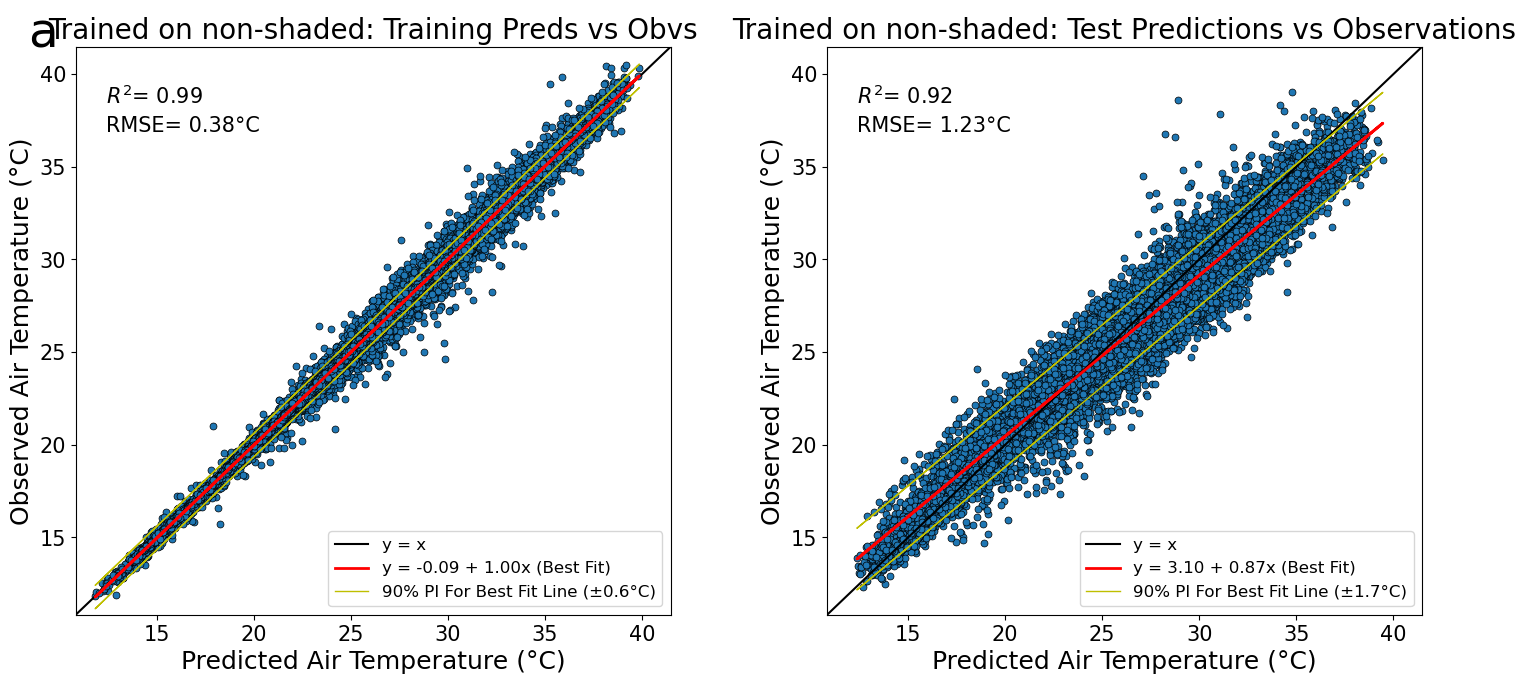

In [4]:
model_name = f'Trained on {to_train_on}:'
y_test_pred_full = y_test_pred_24hrs
y_train_pred_full = y_train_pred_24hrs
y_test_full = y_test_24hrs
y_train_full = y_train_24hrs

######################################################
###### Performance Metrics for the training set ######
######################################################
#rmse
train_rmse = np.sqrt(mean_squared_error(y_train_full, y_train_pred_full))
#r-square~
train_r2 = r2_score(y_train_full, y_train_pred_full)
#mae
train_mae = mean_absolute_error(y_train_full, y_train_pred_full)
print('Training Metrics--', 'RMSE:', train_rmse, 'R-square:', train_r2, 'MAE:', train_mae)

#################################################
###### Performance Metrics for the test set #####
#################################################
#rmse
test_rmse = np.sqrt(mean_squared_error(y_test_full, y_test_pred_full))
#r-square
test_r2 = r2_score(y_test_full, y_test_pred_full)
#mae
test_mae = mean_absolute_error(y_test_full, y_test_pred_full)
print('Test Metrics--', 'RMSE:', test_rmse, 'R-square:', test_r2, 'MAE:', test_mae)

# PLOTS: obvs vs predictions

#plt.rc('font', size=15)          # controls default text sizes
plt.rc('axes', titlesize=20)     # fontsize of the axes title
plt.rc('axes', labelsize=18)    # fontsize of the x and y labels
plt.rc('xtick', labelsize=15)    # fontsize of the tick labels
plt.rc('ytick', labelsize=15)    # fontsize of the tick labels
plt.rc('legend', fontsize=12)    # legend fontsize
plt.rc('figure', titlesize=20)  # fontsize of the figure title

# set plot labels
xlab = 'Predicted Air Temperature (\u00b0C)'
ylab = 'Observed Air Temperature (\u00b0C)'

# set the plot titles
train_title = '{} Training Preds vs Obvs'.format(model_name)
test_title = '{} Test Predictions vs Observations'.format(model_name)
    
# PLOTS: predictions vs obvs with line of best fit 

fig, axes = plt.subplots(1,2, figsize = (16, 8))
fig.tight_layout(pad=7.0)
# training data
axes[0].scatter( y_train_pred_full, y_train_full, s = 25, edgecolors='k', linewidths=0.5)
axes[0].set(title = train_title, 
         xlabel = xlab, ylabel = ylab)

axesmin = min(min(y_train_full), min(y_train_pred_full),min(y_test_full), min(y_test_pred_full)) - 1
axesmax = max(max(y_train_full), max(y_train_pred_full), max(y_test_full), max(y_test_pred_full)) + 1

axes[0].set_xlim([axesmin, axesmax])
axes[0].set_ylim([axesmin, axesmax])
# x = y line
axes[0].plot([axesmin, axesmax],[axesmin, axesmax], color = 'k', label = 'y = x')
# line of best fit
#p, V = np.polyfit(y_train_pred, y_train, 1, cov = True)
#a, b = p[0], p[1]

#get the intercept/ slope of best fit line and prediction interval
sm_model = sm.OLS(y_train_full, sm.add_constant(y_train_pred_full)).fit()
b = sm_model.params[0]
a = sm_model.params[1]
sm_pred = sm_model.get_prediction(sm.add_constant(y_train_pred_full))\
                  .summary_frame(alpha=0.1)

pred_interval_lower = sm_pred.obs_ci_lower.values
pred_interval_upper = sm_pred.obs_ci_upper.values
mean_PI = ((pred_interval_upper - pred_interval_lower)/2).mean()

axes[0].plot(y_train_pred_full, a*y_train_pred_full+b, color='r', linestyle='-', linewidth=2, label = 'y = ' + '{:.2f}'.format(b)+ 
             ' + {:.2f}'.format(a) + 'x (Best Fit)')

#axes[0].plot(y_train_pred, a*y_train_pred+b + np.std(a*y_train_pred+b), color='r', linestyle='--', 
#             linewidth=1, label = 'Fit std')
#axes[0].plot(y_train_pred, a*y_train_pred+b - np.std(a*y_train_pred+b), color='r', linestyle='--', linewidth=1)


axes[0].plot(y_train_pred_full , pred_interval_lower, color = 'y', linestyle='-', linewidth=1
             ,label = '90% PI For Best Fit Line ({}{:.1f}{})'.format(u'\u00B1',mean_PI,'\u00b0C'))
axes[0].plot(y_train_pred_full , pred_interval_upper, color = 'y', linestyle='-', linewidth=1)


#text labels
axes[0].text(0.05, 0.9, '$R^2$= {}'.format(round(train_r2, 2)), fontsize=15, transform=axes[0].transAxes)
axes[0].text(0.05, 0.85, 'RMSE= {}\u00b0C'.format(round(train_rmse, 2)), fontsize=15, transform=axes[0].transAxes)
#axes[0].text(0.05, 0.02, 'y = ' + '{:.2f}'.format(b)+ 
#             ' + {:.2f}'.format(a) + 'x ', 
#             size=15,transform=axes[0].transAxes, color = 'r')

axes[0].legend(loc = 4)
# test data
axes[1].scatter(y_test_pred_full, y_test_full, s = 25, edgecolors='k', linewidths=0.5)
axes[1].set(title = test_title, 
         xlabel = xlab, ylabel = ylab)

axesmin = min(min(y_train_full), min(y_train_pred_full),min(y_test_full), min(y_test_pred_full)) - 1
axesmax = max(max(y_train_full), max(y_train_pred_full), max(y_test_full), max(y_test_pred_full)) + 1

axes[1].set_xlim([axesmin, axesmax])
axes[1].set_ylim([axesmin, axesmax])
axes[1].plot([axesmin, axesmax],[axesmin, axesmax], color = 'k', label = 'y = x')
#get the intercept/ slope of best fit line and prediction interval
sm_model = sm.OLS(y_test_full, sm.add_constant(y_test_pred_full)).fit()
b = sm_model.params[0]
a = sm_model.params[1]
sm_pred = sm_model.get_prediction(sm.add_constant(y_test_pred_full))\
                  .summary_frame(alpha=0.1)

pred_interval_lower = sm_pred.obs_ci_lower.values
pred_interval_upper = sm_pred.obs_ci_upper.values
mean_PI = ((pred_interval_upper - pred_interval_lower)/2).mean()
pred_interval = calc_pred_error(y_test_full, y_test_pred_full)

#axes[1].scatter(y_test_pred, y_test_pred+pred_interval, s = 25, color = 'orange' , edgecolors='k', linewidths=0.5)

axes[1].plot(y_test_pred_full, a*y_test_pred_full +b, color='r', linestyle='-', linewidth=2, label = 'y = ' + '{:.2f}'.format(b)+ 
             ' + {:.2f}'.format(a) + 'x (Best Fit)')

axes[1].plot(y_test_pred_full , pred_interval_lower, color = 'y', linestyle='-', linewidth=1
            ,label = '90% PI For Best Fit Line ({}{:.1f}{})'.format(u'\u00B1',mean_PI,'\u00b0C'))
axes[1].plot(y_test_pred_full , pred_interval_upper, color = 'y', linestyle='-', linewidth=1) 


axes[1].legend(loc = 4)

axes[1].text(0.05, 0.9, '$R^2$= {}'.format(round(test_r2, 2)), fontsize=15, transform=axes[1].transAxes)
axes[1].text(0.05, 0.85, 'RMSE= {}\u00b0C'.format(round(test_rmse, 2)), fontsize=15, transform=axes[1].transAxes)

#add letters for figs
axes[0].text(-0.08, 1, 'a', fontsize=35, transform=axes[0].transAxes)
#axes[1].text(-0.08, 1, 'b', fontsize=35, transform=axes[1].transAxes)
plt.savefig('all_data.png',transparent=True)

In [5]:
import seaborn as sns

In [6]:
# Get feature importances
importances = day_xgb_model.feature_importances_

# Put into a dataframe for readability
feat_importances = pd.DataFrame({
    "Feature": X_train_norm_day.columns,
    "Importance": importances
}).sort_values(by="Importance", ascending=False)

print(feat_importances)

                                           Feature  Importance
15                            relative_humidity_2m    0.114016
11  surface_solar_radiation_downwards_accumulation    0.083001
16                                  temperature_2m    0.082182
17                      total_precipitation_hourly    0.069403
10      surface_thermal_radiation_downwards_hourly    0.068513
8             surface_net_thermal_radiation_hourly    0.061101
5                                     Tree_DSM_SVF    0.054838
4                                             NDMI    0.052763
1                            NDVI_2024SummerMosaic    0.051870
13                         v_component_of_wind_10m    0.050600
9         surface_solar_radiation_downwards_hourly    0.050089
7                                     zenith_angle    0.048875
12                         u_component_of_wind_10m    0.045113
0                            NDBI_2024SummerMosaic    0.042990
14                                   windspeed_10m    0

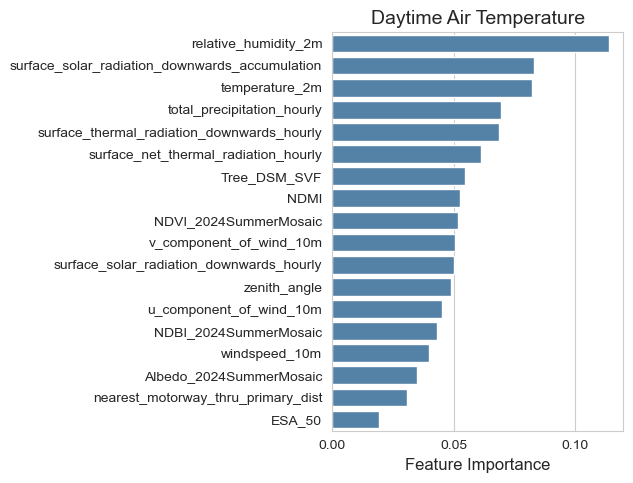

In [7]:
plt.figure(figsize=(8, 5))
sns.set_style("whitegrid")
sns.barplot(
    data=feat_importances,
    y="Feature",                 
    x="Importance",
    color="steelblue"
)

plt.xlabel("Feature Importance", fontsize=12)
plt.ylabel("")                 
plt.title("Daytime Air Temperature", fontsize=14)#, weight='bold')
plt.tight_layout()

plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

plt.savefig('results/at_day_rel_imp.png',transparent=True)

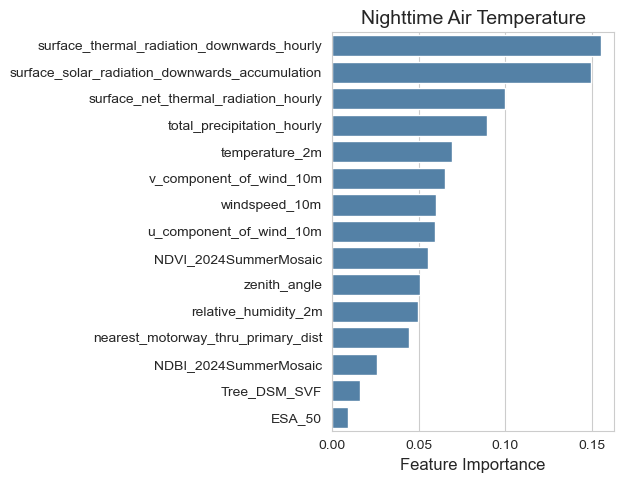

In [8]:
# Get feature importances
importances = night_xgb_model.feature_importances_

# Put into a dataframe for readability
feat_importances = pd.DataFrame({
    "Feature": X_train_norm_night.columns,
    "Importance": importances
}).sort_values(by="Importance", ascending=False)

#print(feat_importances)

plt.figure(figsize=(8, 5))
sns.set_style("whitegrid")
sns.barplot(
    data=feat_importances,
    y="Feature",                 
    x="Importance",
    color="steelblue"
)

plt.xlabel("Feature Importance", fontsize=12)
plt.ylabel("")                 
plt.title("Nighttime Air Temperature", fontsize=14)#, weight='bold')
plt.tight_layout()

plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

plt.savefig('results/at_night_rel_imp.png',transparent=True)

In [9]:
# add in the confidence intervals for the measurement error 
# read in the ci parameters to add in measurment errors 
at_ci_params_filepath = r"C:\Users\Sarah\Documents\Python_Scripts\DDL\Sensor_Network\Heat_model_Durham_Raleigh\src\model_training\SB\AT_ci_params.csv"

at_ci_params = pd.read_csv(at_ci_params_filepath)

# equation for calculating the upper confidence interval for the AT sensor error
def upper_ci(slope, intercept, x_mean, s_err, Sxx, n, t_crit, x_vals):
    x = np.asarray(x_vals)
    ci_width = t_crit * s_err * np.sqrt(1/n + (x - x_mean)**2 / Sxx)
    return slope * x + intercept + ci_width

# Extract CI parameters
day_ci_params = at_ci_params[at_ci_params.Day_Night == 'Day']
slope_day = day_ci_params["slope"].values[0]
intercept_day = at_ci_params["intercept"].values[0]
x_mean_day = at_ci_params["x_mean"].values[0]
s_err_day = at_ci_params["s_err"].values[0]
Sxx_day = at_ci_params["Sxx"].values[0]
n_day = at_ci_params["n"].values[0]
t_crit_day = at_ci_params["t_crit"].values[0]

night_ci_params = at_ci_params[at_ci_params.Day_Night == 'Night']
slope_night = night_ci_params["slope"].values[0]
intercept_night = night_ci_params["intercept"].values[0]
x_mean_night = night_ci_params["x_mean"].values[0]
s_err_night = night_ci_params["s_err"].values[0]
Sxx_night = night_ci_params["Sxx"].values[0]
n_night = night_ci_params["n"].values[0]
t_crit_night = night_ci_params["t_crit"].values[0]

# calculate the day and night measurement error, 95% upper confidence interval  
data_day['AT_Measurement_CI'] = upper_ci(slope_day, intercept_day, x_mean_day, s_err_day, Sxx_day, n_day, t_crit_day, data_day['Diurnal_Range'])
data_night['AT_Measurement_CI'] = upper_ci(slope_night, intercept_night, x_mean_night, s_err_night, Sxx_night, n_night, t_crit_night, data_night['Diurnal_Range'])

# the RH error is set as 95th percentile of standard error between sensors in calibration experiments 
#Day RH 95th percentile std error 0.36235253201311085
#Night RH 95th percentile std error 0.257524304052384

day_rh_measurement_err = 0.36235
night_rh_measurement_err = 0.2575

data_day['RH_Measurement_CI'] = day_rh_measurement_err
data_night['RH_Measurement_CI'] = night_rh_measurement_err

In [72]:
data_day

,Temperature,Relative_Humidity,Date,Hour,Sensor_ID,x,y,Albedo_2024SummerMosaic,CDL_org,CDL_121,...,sin_time,cos_time,utc_datetime,zenith_angle,temp_anom,rh_anom,Diurnal_Range,Predicted_Temperature,AT_Measurement_CI,RH_Measurement_CI
0,23.000000,94.850000,2024-07-01,7,2253106,-78.976169,36.033365,0.180625,123,0,...,0.965926,-2.588190e-01,2024-07-01 11:00:00+00:00,80.410078,0.163761,2.913544,7.918254,23.038686,0.034068,0.36235
1,20.972222,89.583333,2024-07-01,8,2253106,-78.976169,36.033365,0.180625,123,0,...,0.866025,-5.000000e-01,2024-07-01 12:00:00+00:00,68.857161,-0.908177,7.563708,7.918254,20.910289,0.034068,0.36235
2,21.166667,87.916667,2024-07-01,9,2253106,-78.976169,36.033365,0.180625,123,0,...,0.707107,-7.071068e-01,2024-07-01 13:00:00+00:00,56.913466,-0.877155,23.420371,7.918254,20.722310,0.034068,0.36235
3,21.407407,68.733333,2024-07-01,10,2253106,-78.976169,36.033365,0.180625,123,0,...,0.500000,-8.660254e-01,2024-07-01 14:00:00+00:00,44.797136,-1.774415,14.561264,7.918254,21.282308,0.034068,0.36235
4,22.240741,54.400000,2024-07-01,11,2253106,-78.976169,36.033365,0.180625,123,0,...,0.258819,-9.659258e-01,2024-07-01 15:00:00+00:00,32.792268,-2.252247,6.997758,7.918254,22.467674,0.034068,0.36235
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
33853,31.138889,63.600000,2024-08-31,16,2974347,-78.844527,36.011712,0.161167,124,0,...,-0.866025,-5.000000e-01,2024-08-31 20:00:00+00:00,46.553151,1.619531,1.211515,9.276666,33.212277,0.040112,0.36235
33854,30.407407,64.466667,2024-08-31,17,2974347,-78.844527,36.011712,0.161167,124,0,...,-0.965926,-2.588190e-01,2024-08-31 21:00:00+00:00,57.945463,0.816721,3.014543,9.276666,33.708708,0.040112,0.36235
33855,30.370370,64.150000,2024-08-31,18,2974347,-78.844527,36.011712,0.161167,124,0,...,-1.000000,-1.836970e-16,2024-08-31 22:00:00+00:00,69.921847,1.402790,-2.291948,9.276666,32.760000,0.040112,0.36235
33856,29.361111,71.800000,2024-08-31,19,2974347,-78.844527,36.011712,0.161167,124,0,...,-0.965926,2.588190e-01,2024-08-31 23:00:00+00:00,82.057772,1.583047,-3.215080,9.276666,31.275343,0.040112,0.36235


In [73]:
############### Hourly performance ####################
data_all_w_predicted_all = pd.concat([data_day, data_night])
data_all_w_predicted_train = data_all_w_predicted_all[data_all_w_predicted_all.Sensor_ID.isin(train_sensor_ids)].copy()
data_all_w_predicted = data_all_w_predicted_all[data_all_w_predicted_all.Sensor_ID.isin(test_sensor_ids)]

In [74]:
data_all_w_predicted_all

,Temperature,Relative_Humidity,Date,Hour,Sensor_ID,x,y,Albedo_2024SummerMosaic,CDL_org,CDL_121,...,sin_time,cos_time,utc_datetime,zenith_angle,temp_anom,rh_anom,Diurnal_Range,Predicted_Temperature,AT_Measurement_CI,RH_Measurement_CI
0,23.000000,94.850000,2024-07-01,7,2253106,-78.976169,36.033365,0.180625,123,0,...,0.965926,-2.588190e-01,2024-07-01 11:00:00+00:00,80.410078,0.163761,2.913544,7.918254,23.038686,0.034068,0.36235
1,20.972222,89.583333,2024-07-01,8,2253106,-78.976169,36.033365,0.180625,123,0,...,0.866025,-5.000000e-01,2024-07-01 12:00:00+00:00,68.857161,-0.908177,7.563708,7.918254,20.910289,0.034068,0.36235
2,21.166667,87.916667,2024-07-01,9,2253106,-78.976169,36.033365,0.180625,123,0,...,0.707107,-7.071068e-01,2024-07-01 13:00:00+00:00,56.913466,-0.877155,23.420371,7.918254,20.722310,0.034068,0.36235
3,21.407407,68.733333,2024-07-01,10,2253106,-78.976169,36.033365,0.180625,123,0,...,0.500000,-8.660254e-01,2024-07-01 14:00:00+00:00,44.797136,-1.774415,14.561264,7.918254,21.282308,0.034068,0.36235
4,22.240741,54.400000,2024-07-01,11,2253106,-78.976169,36.033365,0.180625,123,0,...,0.258819,-9.659258e-01,2024-07-01 15:00:00+00:00,32.792268,-2.252247,6.997758,7.918254,22.467674,0.034068,0.36235
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
22189,21.768519,99.233333,2024-08-31,6,2974347,-78.844527,36.011712,0.161167,124,0,...,1.000000,6.123234e-17,2024-08-31 10:00:00+00:00,100.032245,-0.082710,0.697729,9.276666,22.105027,0.010554,0.25750
22190,21.620370,99.233333,2024-08-31,7,2974347,-78.844527,36.011712,0.161167,124,0,...,0.965926,-2.588190e-01,2024-08-31 11:00:00+00:00,88.252829,-0.127959,0.278893,9.276666,21.880576,0.010554,0.25750
22191,25.805556,88.500000,2024-08-31,21,2974347,-78.844527,36.011712,0.161167,124,0,...,-0.707107,7.071068e-01,2024-09-01 01:00:00+00:00,105.606812,-0.351516,5.141037,9.276666,26.656027,0.010554,0.25750
22192,25.435185,89.633333,2024-08-31,22,2974347,-78.844527,36.011712,0.161167,124,0,...,-0.500000,8.660254e-01,2024-09-01 02:00:00+00:00,116.319336,-0.230842,5.969673,9.276666,25.654031,0.010554,0.25750


In [75]:
# compute hourly confidence intervals

    Hour      RMSE       MAE       MBE   MPE (%)        R²     CI_AT     CI_RH
0      0  0.903981  0.653487 -0.402074 -1.693534  0.891773  0.011410  0.257500
1      1  0.828924  0.601252 -0.360316 -1.559688  0.908643  0.011377  0.257500
2      2  0.778988  0.559531 -0.336344 -1.490550  0.921237  0.011377  0.257500
3      3  0.742369  0.535048 -0.328245 -1.490775  0.930867  0.011377  0.257500
4      4  0.725024  0.516764 -0.312863 -1.449089  0.936621  0.011375  0.257500
5      5  0.702087  0.498000 -0.305859 -1.448717  0.943051  0.011375  0.257500
6      6  0.676233  0.487321 -0.311997 -1.491834  0.948639  0.011377  0.257500
7      7  0.600241  0.432728 -0.228100 -1.094129  0.960592  0.042416  0.357028
8      8  0.662420  0.451357 -0.008857 -0.042017  0.949049  0.043727  0.362350
9      9  1.229060  0.906485  0.582803  2.670463  0.792467  0.043727  0.362350
10    10  1.760173  1.384299  1.289368  5.300256  0.542839  0.043727  0.362350
11    11  1.740061  1.501503  1.435960  5.414413  0.

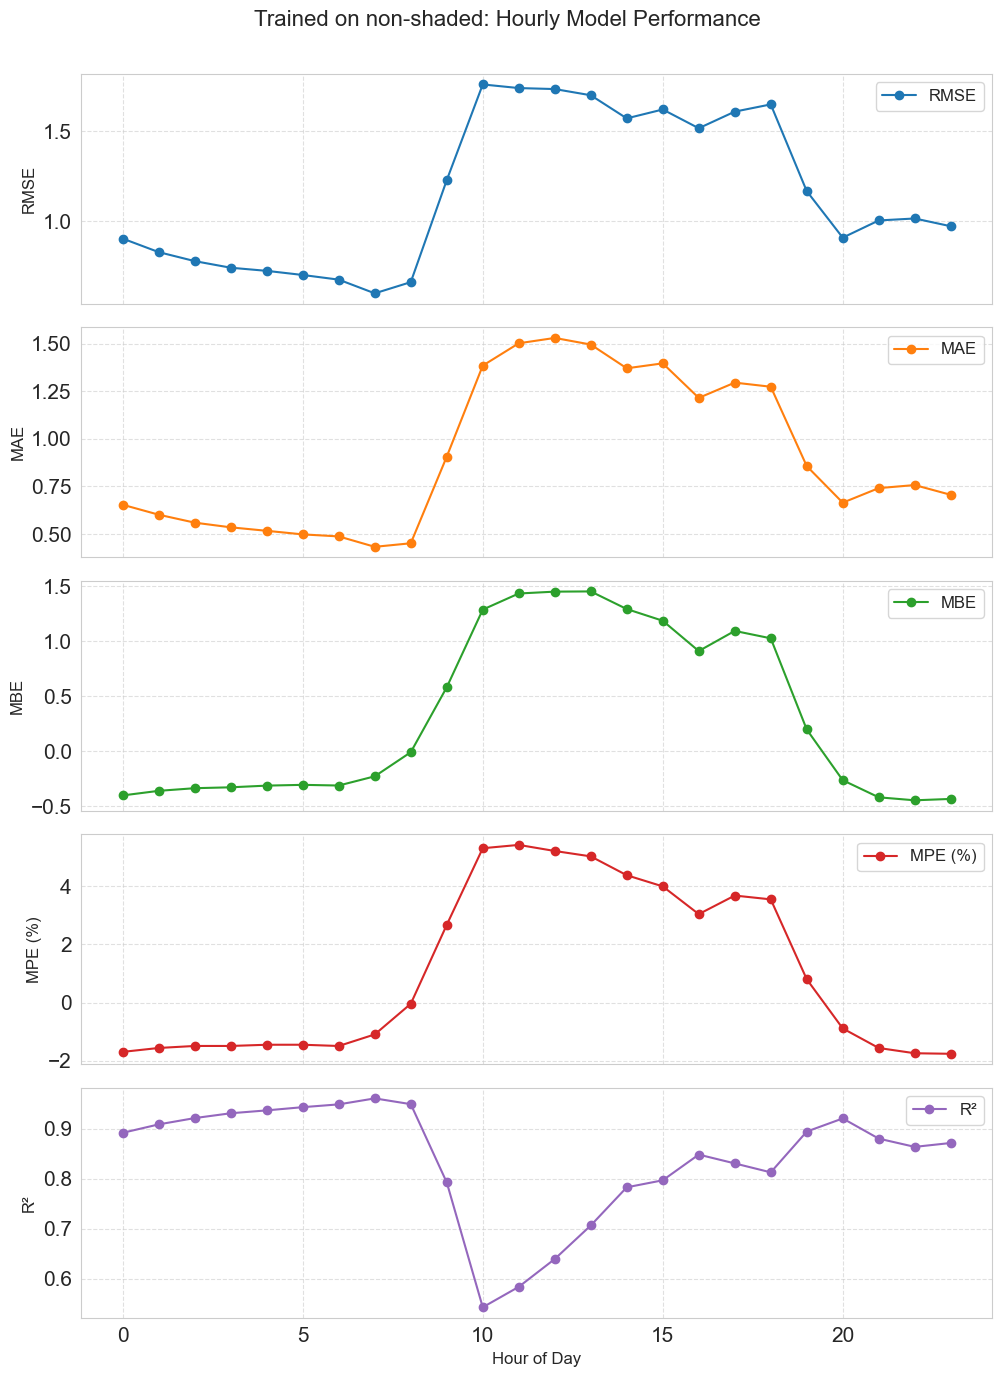

In [76]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt

def calc_metrics(obs, pred):
    rmse = np.sqrt(mean_squared_error(obs, pred))
    mae = mean_absolute_error(obs, pred)
    mbe = np.mean(pred - obs)
    mpe = np.mean((pred - obs) / obs) * 100     # %
    r2  = r2_score(obs, pred)
    return rmse, mae, mbe, mpe, r2

# --- Compute hourly metrics ---
hourly_stats = []
for hour, group in data_all_w_predicted.groupby('Hour'):
    rmse, mae, mbe, mpe, r2 = calc_metrics(group['Temperature'], group['Predicted_Temperature'])
    ci_at = group['AT_Measurement_CI'].mean()
    ci_rh = group['RH_Measurement_CI'].mean()
    hourly_stats.append({
        'Hour': hour,
        'RMSE': rmse,
        'MAE': mae,
        'MBE': mbe,
        'MPE (%)': mpe,
        'R²': r2,
        'CI_AT':ci_at,
        'CI_RH':ci_rh,
    })

hourly_stats_df = pd.DataFrame(hourly_stats).sort_values('Hour')

print(hourly_stats_df)

# --- Create subplots: one subplot for each metric ---
metrics = ['RMSE', 'MAE', 'MBE', 'MPE (%)', 'R²']
colors  = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple']

fig, axes = plt.subplots(len(metrics), 1, figsize=(10, 14), sharex=True)

for ax, metric, color in zip(axes, metrics, colors):
    ax.plot(hourly_stats_df['Hour'], hourly_stats_df[metric],
            marker='o', color=color, label=metric)
    ax.set_ylabel(metric, fontsize=12)
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.legend(loc='best')

axes[-1].set_xlabel('Hour of Day', fontsize=12)
fig.suptitle(f'Trained on {to_train_on}: Hourly Model Performance', fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.97])

hourly_stats_df.to_csv(f'results/AT_hourly_test_data_stats_{to_train_on}.csv', index = False)

In [77]:
pwd

'C:\\Users\\Sarah\\Documents\\Python_Scripts\\DDL\\Sensor_Network\\Heat_model_Durham_Raleigh\\src\\model_training\\SB'

In [78]:
data_night

,Temperature,Relative_Humidity,Date,Hour,Sensor_ID,x,y,Albedo_2024SummerMosaic,CDL_org,CDL_121,...,sin_time,cos_time,utc_datetime,zenith_angle,temp_anom,rh_anom,Diurnal_Range,Predicted_Temperature,AT_Measurement_CI,RH_Measurement_CI
0,24.527778,94.983333,2024-07-01,1,2253106,-78.976169,36.033365,0.180625,123,0,...,0.258819,9.659258e-01,2024-07-01 05:00:00+00:00,120.757221,-0.050000,-1.523960,7.918254,24.504431,0.009239,0.2575
1,24.435185,94.766667,2024-07-01,2,2253106,-78.976169,36.033365,0.180625,123,0,...,0.500000,8.660254e-01,2024-07-01 06:00:00+00:00,120.170250,0.327925,-2.584690,7.918254,24.199918,0.009239,0.2575
2,24.046296,94.600000,2024-07-01,3,2253106,-78.976169,36.033365,0.180625,123,0,...,0.707107,7.071068e-01,2024-07-01 07:00:00+00:00,116.347512,-0.185052,-3.926910,7.918254,23.855893,0.009239,0.2575
3,23.870370,96.800000,2024-07-01,4,2253106,-78.976169,36.033365,0.180625,123,0,...,0.866025,5.000000e-01,2024-07-01 08:00:00+00:00,109.824092,-0.157989,-2.739076,7.918254,23.828682,0.009239,0.2575
4,23.759259,97.666667,2024-07-01,5,2253106,-78.976169,36.033365,0.180625,123,0,...,0.965926,2.588190e-01,2024-07-01 09:00:00+00:00,101.283236,-0.427751,-0.726573,7.918254,23.778026,0.009239,0.2575
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
22189,21.768519,99.233333,2024-08-31,6,2974347,-78.844527,36.011712,0.161167,124,0,...,1.000000,6.123234e-17,2024-08-31 10:00:00+00:00,100.032245,-0.082710,0.697729,9.276666,22.105027,0.010554,0.2575
22190,21.620370,99.233333,2024-08-31,7,2974347,-78.844527,36.011712,0.161167,124,0,...,0.965926,-2.588190e-01,2024-08-31 11:00:00+00:00,88.252829,-0.127959,0.278893,9.276666,21.880576,0.010554,0.2575
22191,25.805556,88.500000,2024-08-31,21,2974347,-78.844527,36.011712,0.161167,124,0,...,-0.707107,7.071068e-01,2024-09-01 01:00:00+00:00,105.606812,-0.351516,5.141037,9.276666,26.656027,0.010554,0.2575
22192,25.435185,89.633333,2024-08-31,22,2974347,-78.844527,36.011712,0.161167,124,0,...,-0.500000,8.660254e-01,2024-09-01 02:00:00+00:00,116.319336,-0.230842,5.969673,9.276666,25.654031,0.010554,0.2575


In [79]:
data_all_w_predicted

,Temperature,Relative_Humidity,Date,Hour,Sensor_ID,x,y,Albedo_2024SummerMosaic,CDL_org,CDL_121,...,sin_time,cos_time,utc_datetime,zenith_angle,temp_anom,rh_anom,Diurnal_Range,Predicted_Temperature,AT_Measurement_CI,RH_Measurement_CI
899,24.083333,97.533333,2024-07-01,7,2401086,-78.906959,35.891580,0.163733,122,0,...,0.965926,-2.588190e-01,2024-07-01 11:00:00+00:00,80.410078,1.247095,5.596877,7.918254,23.223048,0.034068,0.36235
900,21.879630,89.616667,2024-07-01,8,2401086,-78.906959,35.891580,0.163733,122,0,...,0.866025,-5.000000e-01,2024-07-01 12:00:00+00:00,68.857161,-0.000769,7.597042,7.918254,21.466636,0.034068,0.36235
901,21.231481,86.766667,2024-07-01,9,2401086,-78.906959,35.891580,0.163733,122,0,...,0.707107,-7.071068e-01,2024-07-01 13:00:00+00:00,56.913466,-0.812340,22.270371,7.918254,20.919599,0.034068,0.36235
902,21.064815,67.816667,2024-07-01,10,2401086,-78.906959,35.891580,0.163733,122,0,...,0.500000,-8.660254e-01,2024-07-01 14:00:00+00:00,44.797136,-2.117008,13.644597,7.918254,21.139529,0.034068,0.36235
903,22.212963,59.066667,2024-07-01,11,2401086,-78.906959,35.891580,0.163733,122,0,...,0.258819,-9.659258e-01,2024-07-01 15:00:00+00:00,32.792268,-2.280025,11.664424,7.918254,22.630350,0.034068,0.36235
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
22189,21.768519,99.233333,2024-08-31,6,2974347,-78.844527,36.011712,0.161167,124,0,...,1.000000,6.123234e-17,2024-08-31 10:00:00+00:00,100.032245,-0.082710,0.697729,9.276666,22.105027,0.010554,0.25750
22190,21.620370,99.233333,2024-08-31,7,2974347,-78.844527,36.011712,0.161167,124,0,...,0.965926,-2.588190e-01,2024-08-31 11:00:00+00:00,88.252829,-0.127959,0.278893,9.276666,21.880576,0.010554,0.25750
22191,25.805556,88.500000,2024-08-31,21,2974347,-78.844527,36.011712,0.161167,124,0,...,-0.707107,7.071068e-01,2024-09-01 01:00:00+00:00,105.606812,-0.351516,5.141037,9.276666,26.656027,0.010554,0.25750
22192,25.435185,89.633333,2024-08-31,22,2974347,-78.844527,36.011712,0.161167,124,0,...,-0.500000,8.660254e-01,2024-09-01 02:00:00+00:00,116.319336,-0.230842,5.969673,9.276666,25.654031,0.010554,0.25750


In [80]:
data_all_w_predicted = pd.concat([data_day, data_night])
data_all_w_predicted = data_all_w_predicted[data_all_w_predicted.Sensor_ID.isin(test_sensor_ids)]
# Calculate residuals
data_all_w_predicted['residual'] = (
    data_all_w_predicted['Temperature'] - data_all_w_predicted['Predicted_Temperature']
)

# Define desired confidence level
#alpha = 0.05    # for 95% prediction interval
alpha = 0.1    # for 90% prediction interval

# --- Compute fixed residual quantiles for each hour across all days ---
hourly_residual_q = (
    data_all_w_predicted
    .groupby('Hour')['residual']
    .quantile([alpha/2, 1 - alpha/2])
    .unstack()
    .rename(columns={alpha/2: 'lower_residual_q', 1 - alpha/2: 'upper_residual_q'})
    .reset_index()
)

# Merge these hourly quantiles back into main DataFrame
data_all_w_predicted = data_all_w_predicted.merge(hourly_residual_q, on='Hour', how='left')

# Compute PIs using the fixed hourly quantiles
data_all_w_predicted['PI_lower'] = (
    data_all_w_predicted['Predicted_Temperature'] + data_all_w_predicted['lower_residual_q']
)
data_all_w_predicted['PI_upper'] = (
    data_all_w_predicted['Predicted_Temperature'] + data_all_w_predicted['upper_residual_q']
)

data_all_w_predicted['Measurement_CI_lower'] = (
    data_all_w_predicted['PI_lower'] - data_all_w_predicted['AT_Measurement_CI']
)
data_all_w_predicted['Measurement_CI_upper'] = (
    data_all_w_predicted['PI_upper'] + data_all_w_predicted['AT_Measurement_CI']
)

# --- Prepare an hourly summary for plotting ---
hourly_summary = (
    data_all_w_predicted
    .groupby('Hour')
    .agg({
        'Temperature': 'mean',
        'Predicted_Temperature': 'mean',
        'PI_lower': 'mean',
        'PI_upper': 'mean',
        'Measurement_CI_lower':'mean',
        'Measurement_CI_upper':'mean',
    })
    .reset_index()
)



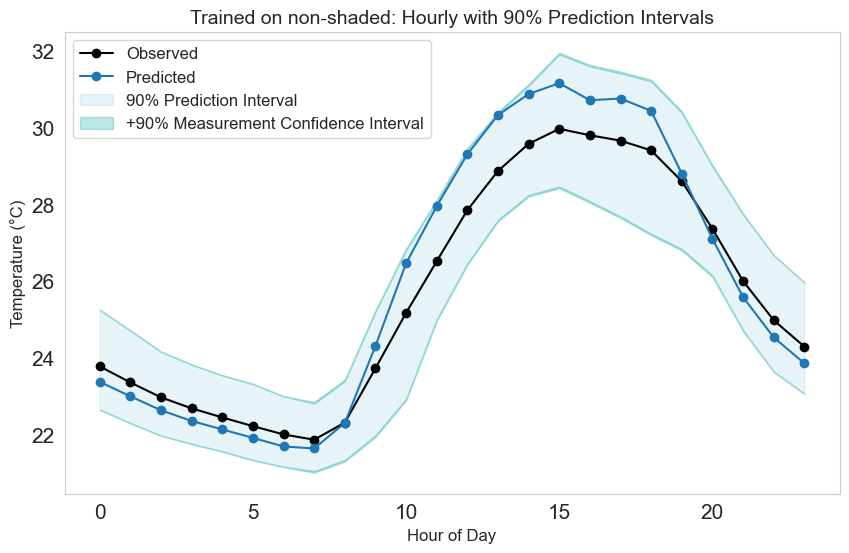

In [81]:
plt.figure(figsize=(10,6))

# Observed mean
plt.plot(hourly_summary['Hour'], hourly_summary['Temperature'],
         marker='o', color='black', label='Observed')

# Predicted mean
plt.plot(hourly_summary['Hour'], hourly_summary['Predicted_Temperature'],
         marker='o', color='tab:blue', label='Predicted')

# Fixed hourly prediction interval band
plt.fill_between(hourly_summary['Hour'],
                 hourly_summary['PI_lower'],
                 hourly_summary['PI_upper'],
                 color='lightblue', alpha=0.3,
                 label='90% Prediction Interval')

plt.fill_between(hourly_summary['Hour'],
                 hourly_summary['PI_upper'],
                 hourly_summary['Measurement_CI_upper'],
                 color='lightseagreen', alpha=0.3,
                 label='+90% Measurement Confidence Interval')

plt.fill_between(hourly_summary['Hour'],
                 hourly_summary['Measurement_CI_lower'],
                 hourly_summary['PI_lower'],
                 color='lightseagreen', alpha=0.3,)
                 #label='+90% Measurement Confidence Interval')


plt.xlabel('Hour of Day', fontsize=12)
plt.ylabel('Temperature (°C)', fontsize=12)
plt.title(f'Trained on {to_train_on}: Hourly with 90% Prediction Intervals', fontsize=14)
#plt.grid(True, linestyle='--', alpha=0.6)
plt.grid(False)
plt.legend()

plt.tick_params(axis='both', which='both',color='black', )
plt.savefig(f'results/at_hourly_perf_{to_train_on}.png',transparent=True)
hourly_summary.to_csv(f'results/AT_hourly_summary_{to_train_on}.csv', index = False)

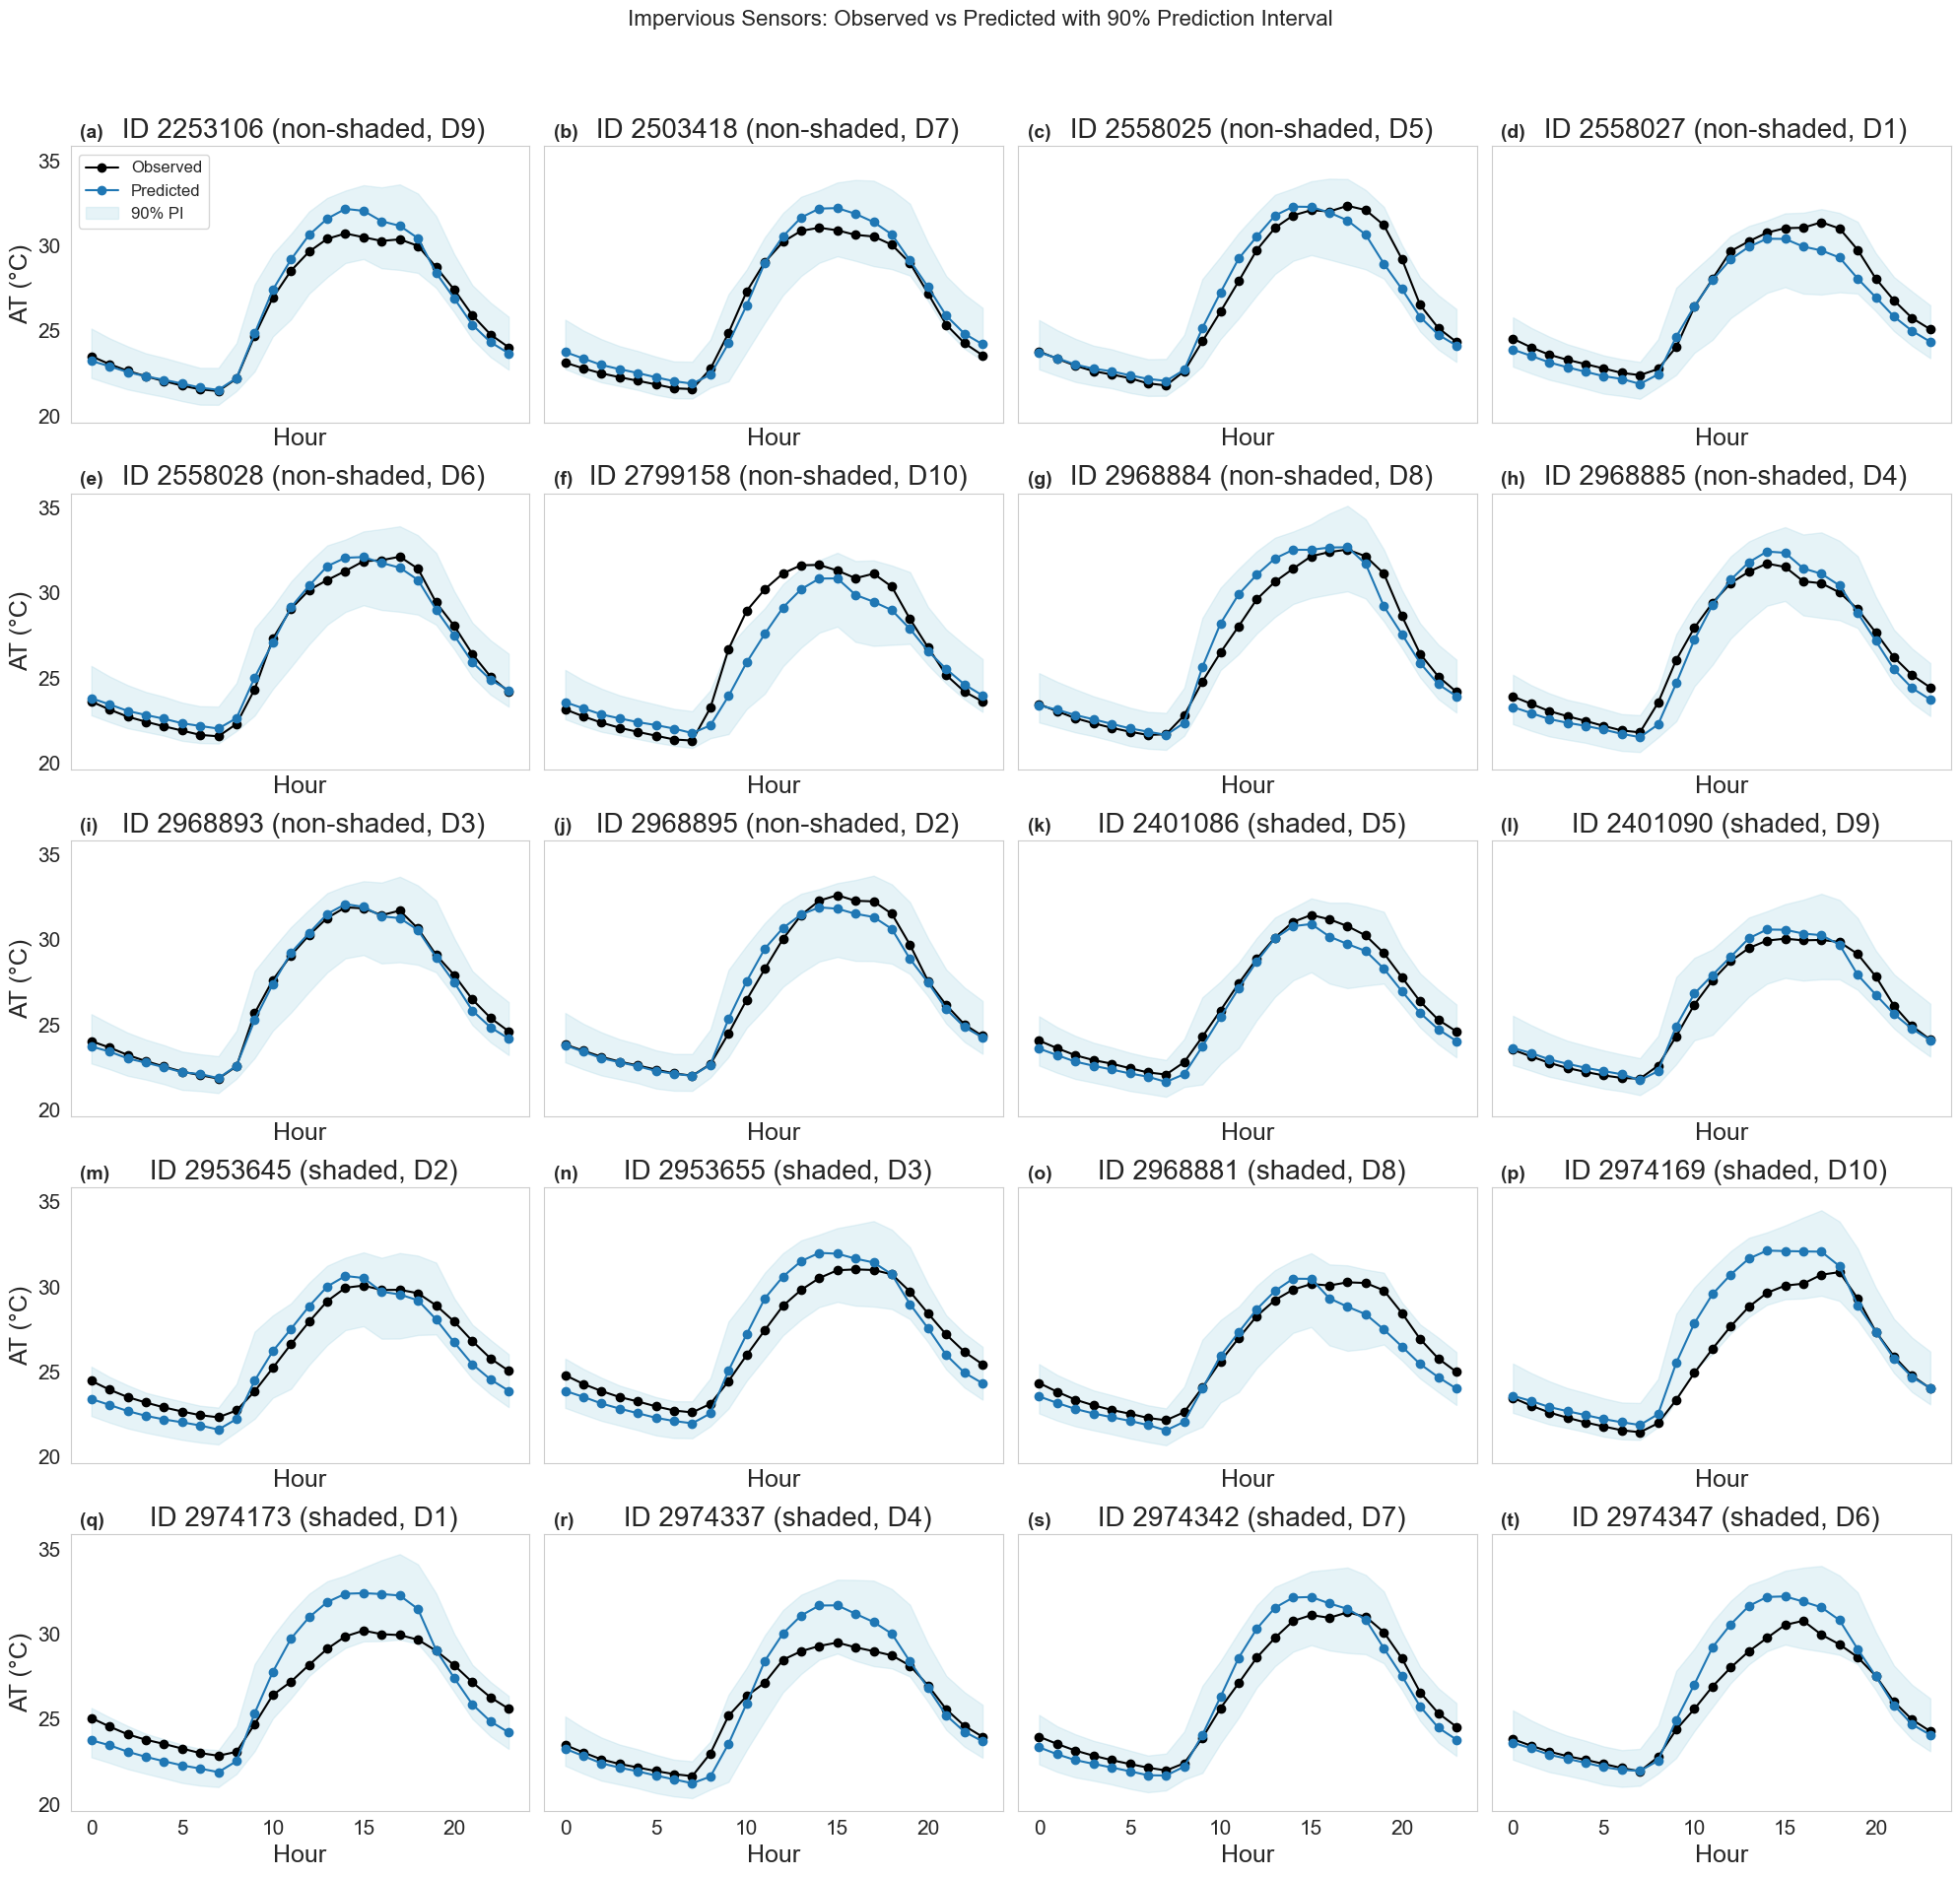

In [26]:
import string

# Filter for impervious surfaces only
impervious_data = shading_location_split_hourly_summary[
    shading_location_split_hourly_summary['Landcover Type'] == 'impervious'
]

# Get unique sensors
sensors = impervious_data['Sensor_ID'].unique()
n_sensors = len(sensors)

# Determine grid size (square-ish)
n_cols = 4
n_rows = int(np.ceil(n_sensors / n_cols))
labels = list(string.ascii_lowercase)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(5*n_cols, 4*n_rows), sharey=True, sharex=True)
axes = axes.flatten()  # flatten in case of 2D array

for i, sensor in enumerate(sensors):
    ax = axes[i]
    sensor_data = impervious_data[impervious_data['Sensor_ID'] == sensor]
    sensor_hourly = sensor_data.groupby('Hour').mean(numeric_only=True).reset_index()

    # Observed
    ax.plot(sensor_hourly['Hour'], sensor_hourly['Temperature'],
            marker='o', color='black', label='Observed')

    # Predicted
    ax.plot(sensor_hourly['Hour'], sensor_hourly['Predicted_Temperature'],
            marker='o', color='tab:blue', label='Predicted')

    # Prediction Interval
    ax.fill_between(sensor_hourly['Hour'],
                    sensor_hourly['PI_lower'],
                    sensor_hourly['PI_upper'],
                    color='lightblue', alpha=0.3, label='90% PI')

    ax.text(0.02, 1.08, f'({labels[i]})', transform=ax.transAxes,
            fontsize=14, fontweight='bold', va='top', ha='left')
    shade_type = sensor_data['Shade Type'].iloc[0]
    decile = sensor_info[sensor_info['Sensor Serial Number'] ==sensor]['Decile Group'].values[0]
    ax.set_title(f' ID {sensor} ({shade_type}, D{decile})')
    ax.set_xlabel('Hour')
    # Only label y-axis on the leftmost column
    if i % n_cols == 0:
        ax.set_ylabel('AT (°C)')
    else:
        ax.set_ylabel('')
    ax.grid(False)

axes[0].legend()
# Remove empty subplots if sensors < n_rows*n_cols
for j in range(i+1, n_rows*n_cols):
    fig.delaxes(axes[j])

fig.suptitle('Impervious Sensors: Observed vs Predicted with 90% Prediction Interval', fontsize=16)
fig.tight_layout(rect=[0, 0.03, 1, 0.95]) 


In [2]:
# read in the ci parameters to add in measurment errors 
at_ci_params_filepath = r"C:\Users\Sarah\Documents\Python_Scripts\DDL\Sensor_Network\Heat_model_Durham_Raleigh\src\model_training\SB\AT_ci_params.csv"

at_ci_params = pd.read_csv(at_ci_params_filepath)

# equation for calculating the upper confidence interval for the AT sensor error
def upper_ci(slope, intercept, x_mean, s_err, Sxx, n, t_crit, x_pred):
    x = np.asarray(x_pred)
    ci_width = t_crit * s_err * np.sqrt(1/n + (x - x_mean)**2 / Sxx)
    return slope * x + intercept + ci_width

# Extract CI parameters
day_ci_params = at_ci_params[at_ci_params.Day_Night == 'Day']
slope_day = day_ci_params["slope"].values[0]
intercept_day = at_ci_params["intercept"].values[0]
x_mean_day = at_ci_params["x_mean"].values[0]
s_err_day = at_ci_params["s_err"].values[0]
Sxx_day = at_ci_params["Sxx"].values[0]
n_day = at_ci_params["n"].values[0]
t_crit_day = at_ci_params["t_crit"].values[0]

night_ci_params = at_ci_params[at_ci_params.Day_Night == 'Night']
slope_night = night_ci_params["slope"].values[0]
intercept_night = night_ci_params["intercept"].values[0]
x_mean_night = night_ci_params["x_mean"].values[0]
s_err_night = night_ci_params["s_err"].values[0]
Sxx_night = night_ci_params["Sxx"].values[0]
n_night = night_ci_params["n"].values[0]
t_crit_night = night_ci_params["t_crit"].values[0]

# the RH error is set as 95th percentile of standard error between sensors in calibration experiments 
#Day RH 95th percentile std error 0.36235253201311085
#Night RH 95th percentile std error 0.257524304052384

day_rh_measurement_err = 0.36235
night_rh_measurement_err = 0.2575

In [11]:
from matplotlib.ticker import MaxNLocator
from matplotlib.ticker import MultipleLocator

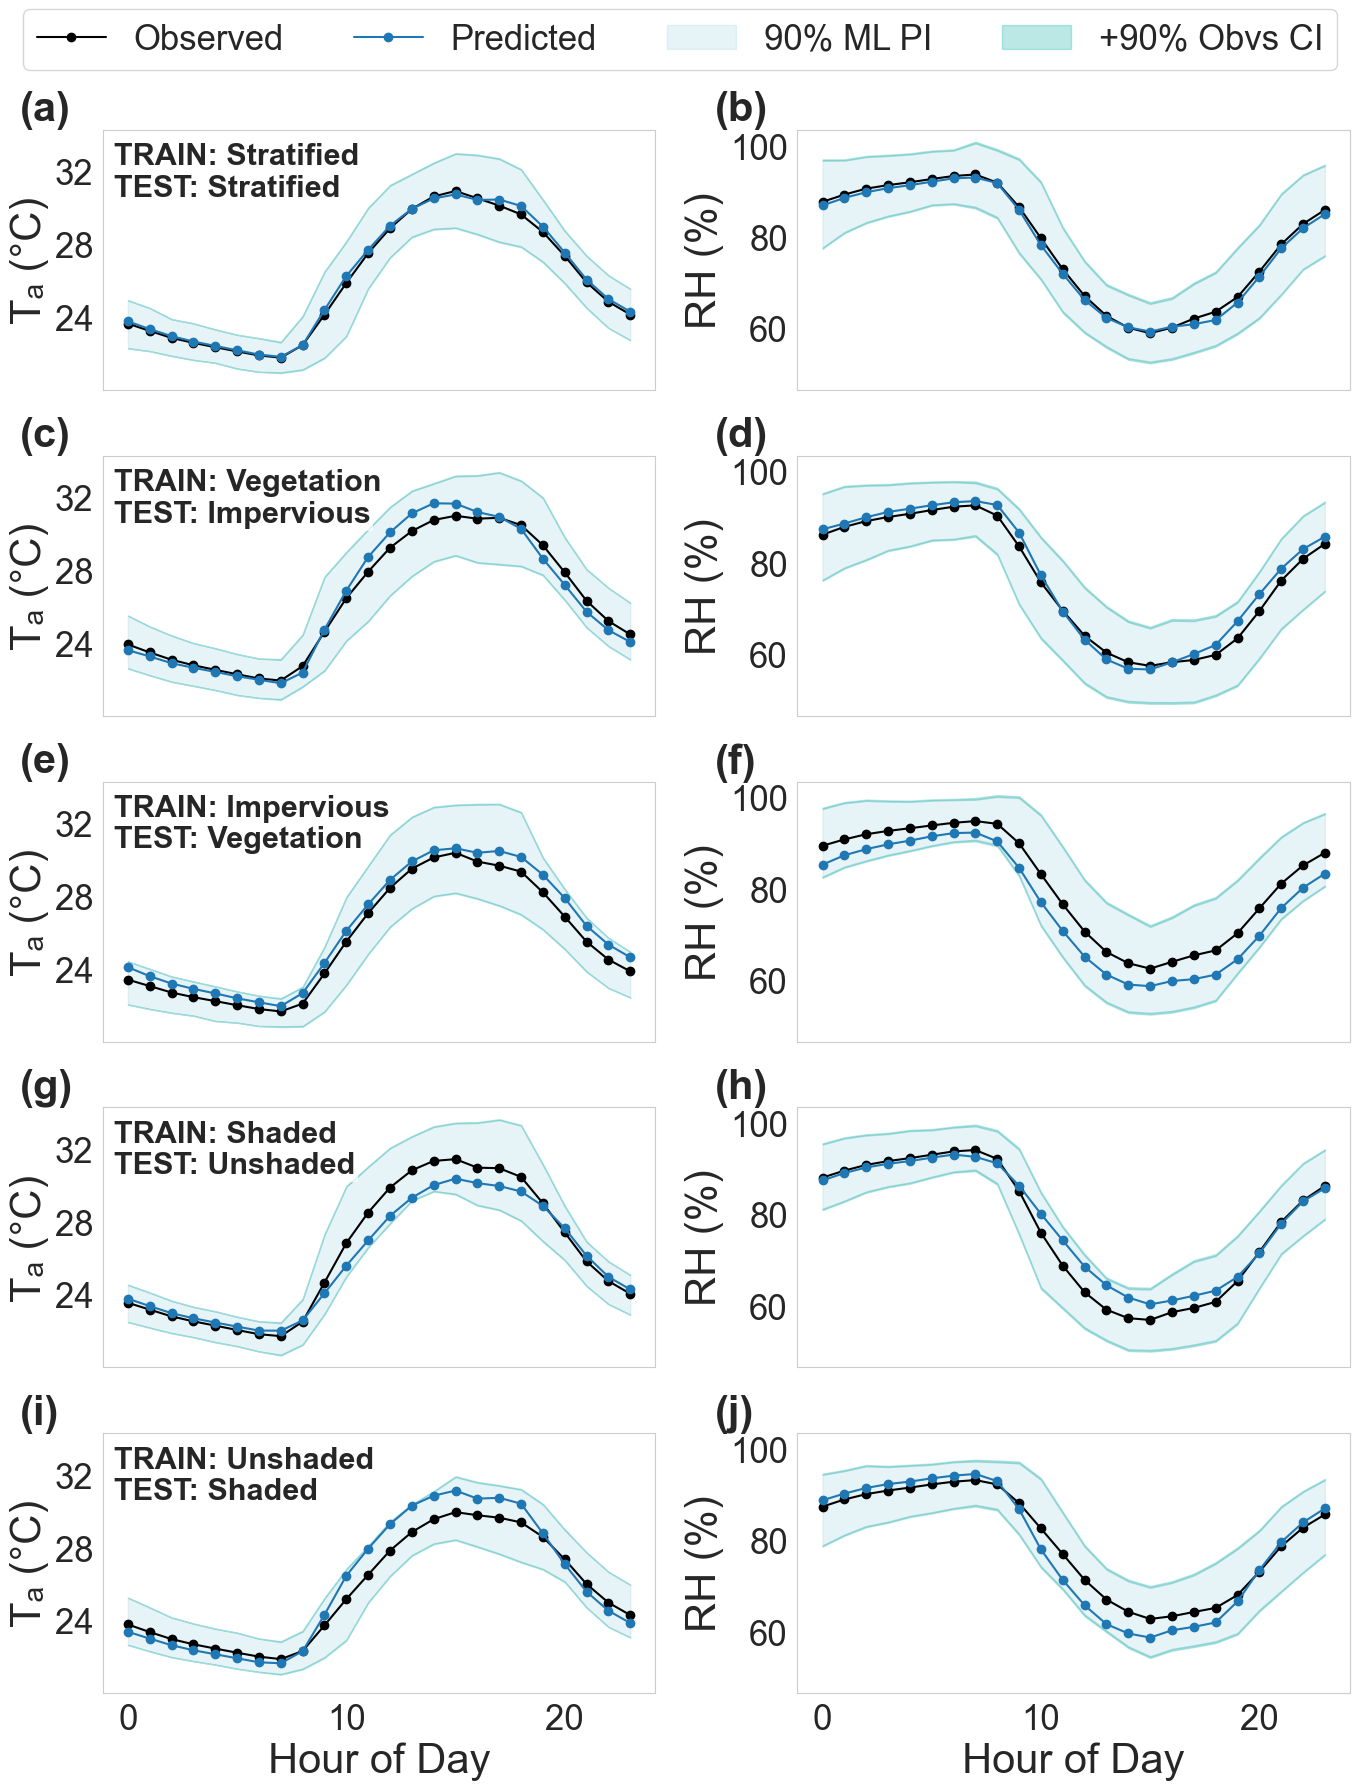

In [24]:
##### Creating plots for the paper - showing all the hourly performance for the main model, and all the landcover/ shading bias tests
plt.rcParams.update({
    'font.size': 20,
    'axes.labelsize': 25,
    'axes.titlesize': 25,
    'xtick.labelsize': 25,
    'ytick.labelsize': 25,
    'legend.fontsize': 25
})
# all LC 

all_lc_at_hourly_summary = pd.read_csv('results/AT_hourly_summary.csv')
all_lc_rh_hourly_summary = pd.read_csv('results/RH_hourly_summary.csv')
all_lc_rh_hourly_summary = all_lc_rh_hourly_summary.rename(columns = {'Predicted_relative_humidity':'Predicted_Relative_Humidity'})


training_list = ['vegetation','impervious','shaded','non-shaded']

for to_train_on in training_list:
    at_hourly_summary = pd.read_csv(f'results/AT_hourly_summary_{to_train_on}.csv')
    rh_hourly_summary = pd.read_csv(f'results/RH_hourly_summary_{to_train_on}.csv')

datasets = ['all_LC'] + training_list
titles_1 = ['TRAIN: Stratified',
        'TRAIN: Vegetation',
          'TRAIN: Impervious',
          'TRAIN: Shaded',
          'TRAIN: Unshaded']

titles_2 = ['TEST: Stratified',
        'TEST: Impervious',
          'TEST: Vegetation',
          'TEST: Unshaded',
          'TEST: Shaded']



fig, axes = plt.subplots(5, 2, figsize=(14, 18), sharey='col', sharex=True)
for i, dataset in enumerate(datasets):
    if dataset == 'all_LC':
        at_data = all_lc_at_hourly_summary
        rh_data = all_lc_rh_hourly_summary
    else:
        at_data = pd.read_csv(f'results/AT_hourly_summary_{dataset}.csv')
        rh_data = pd.read_csv(f'results/RH_hourly_summary_{dataset}.csv')
    
    
    # AT in left column
    ax_at = axes[i, 0]
    ax_at.plot(at_data['Hour'], at_data['Temperature'], 'o-', color='black', label='Observed')
    ax_at.plot(at_data['Hour'], at_data['Predicted_Temperature'], 'o-', color='tab:blue', label='Predicted')
    ax_at.fill_between(at_data['Hour'], at_data['PI_lower'], at_data['PI_upper'], color='lightblue', alpha=0.3, label = '90% ML PI')
    
    ax_at.fill_between(at_data['Hour'],
                 at_data['PI_upper'],
                 at_data['Measurement_CI_upper'],
                 color='lightseagreen', alpha=0.3,
                 label='+90% Obvs CI')

    ax_at.fill_between(at_data['Hour'],
                 at_data['Measurement_CI_lower'],
                 at_data['PI_lower'],
                 color='lightseagreen', alpha=0.3,)
                 #label='+90% Measurement Confidence Interval')
    
    #ax_at.set_title('AT' if i == 0 else '', fontsize=14)
    ax_at.grid(False)
    ax_at.set_ylabel('Tₐ (°C)', fontsize=30)
    ax_at.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax_at.yaxis.set_major_locator(MultipleLocator(4))
    #ax_at.set_ylim(top=32)
    #if i == 0:
    #    ax_at.legend(fontsize = 15, ncols =1, bbox_to_anchor =(0.38,0.82))
    
    ax_at.text(
            0.02, 0.95,               
            titles_1[i],               
            ha='left', va='top',
            transform=ax_at.transAxes,
            fontsize=22,
            fontweight='semibold',
            bbox=dict(facecolor='white', edgecolor='none', alpha=0.7, pad=2)
        )
    ax_at.text(
            0.02, 0.83,               
            titles_2[i],               
            ha='left', va='top',
            transform=ax_at.transAxes,
            fontsize=22,
            fontweight='semibold',
            bbox=dict(facecolor='white', edgecolor='none', alpha=0.7, pad=2)
        )
    
    # Rh right column
    ax_rh = axes[i, 1]
    ax_rh.plot(rh_data['Hour'], rh_data['Relative_Humidity'], 'o-', color='black', label='Observed')
    ax_rh.plot(rh_data['Hour'], rh_data['Predicted_Relative_Humidity'], 'o-', color='tab:blue', label='Predicted')
    ax_rh.fill_between(rh_data['Hour'], rh_data['PI_lower'], rh_data['PI_upper'], color='lightblue', alpha=0.3)
    ax_rh.fill_between(rh_data['Hour'],
                 rh_data['PI_upper'],
                 rh_data['Measurement_CI_upper'],
                 color='lightseagreen', alpha=0.3,
                 label='+90% Measurement CI')

    ax_rh.fill_between(rh_data['Hour'],
                 rh_data['Measurement_CI_lower'],
                 rh_data['PI_lower'],
                 color='lightseagreen', alpha=0.3,)
                 #label='+90% Measurement Confidence Interval')
    #ax_rh.set_title('RH' if i == 0 else '', fontsize=14)
    ax_rh.grid(False)
    ax_rh.set_ylabel('RH (%)', fontsize=30)
    ax_rh.yaxis.set_major_locator(MultipleLocator(20))
    #if i == 0:
    #    ax_rh.legend()

# shared legend
handles, labels = ax_at.get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc='upper center',
    ncol=4,
    bbox_to_anchor=(0.5, 1.01),
    frameon=True
)
    
# x label shared for all
for ax in axes[-1, :]:
    ax.set_xlabel('Hour of Day', fontsize=30)

# add letter labels to the top corners
letter_labels = ['a','b','c','d','e','f','g','h','i','j']
for idx, ax in enumerate(axes.flatten()):
    ax.text(
        -0.15, 1.15, f'({letter_labels[idx]})',   # position (top-left inside each subplot)
        transform=ax.transAxes,
        ha='left', va='top',
        fontsize=30,
        fontweight='bold'
    )

#fig.suptitle('Hourly Model Performance', fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.97])
#plt.savefig('results/ALL_hourly_perf_10_subplots.png',transparent=True)

plt.savefig(r'C:\Users\Sarah\OneDrive - University of North Carolina at Chapel Hill\Documents\DDL\Science_Projects\Sensors\ML_model_paper\ALL_hourly_perf_10_subplots.png', 
            format='png', dpi=1200, bbox_inches='tight')


In [105]:
(all_lc_at_hourly_summary.PI_upper - all_lc_at_hourly_summary.Predicted_Temperature)

0     1.153230
1     1.155801
2     0.930561
3     0.993378
4     0.904619
5     0.847409
6     0.892775
7     0.790207
8     1.568542
9     2.081852
10    1.877997
11    2.291379
12    2.204623
13    1.894889
14    1.940591
15    2.230007
16    2.455334
17    2.232230
18    1.988234
19    1.457252
20    1.179734
21    1.297669
22    1.298930
23    1.249663
dtype: float64

In [27]:
import pandas as pd

datasets = ['all_LC', 'vegetation', 'impervious', 'shaded', 'non-shaded']

col_labels = {
    'all_LC': 'Stratified',
    'vegetation': 'Vegetation Trained',
    'impervious': 'Impervious Trained',
    'shaded': 'Shaded Trained',
    'non-shaded': 'Unshaded Trained'
}

at_wide = None
rh_wide = None

for dataset in datasets:

    # load data
    if dataset == 'all_LC':
        at_data = pd.read_csv('results/AT_hourly_summary.csv')
        rh_data = pd.read_csv('results/RH_hourly_summary.csv')
        rh_data = rh_data.rename(
            columns={'Predicted_relative_humidity': 'Predicted_Relative_Humidity'}
        )
    else:
        at_data = pd.read_csv(f'results/AT_hourly_summary_{dataset}.csv')
        rh_data = pd.read_csv(f'results/RH_hourly_summary_{dataset}.csv')

    # compute hourly MBE
    at_mbe = at_data['Predicted_Temperature'] - at_data['Temperature']
    rh_mbe = rh_data['Predicted_Relative_Humidity'] - rh_data['Relative_Humidity']

    # initialize tables
    if at_wide is None:
        at_wide = pd.DataFrame({'Hour': at_data['Hour']})
        rh_wide = pd.DataFrame({'Hour': rh_data['Hour']})

    # add columns
    at_wide[col_labels[dataset]] = at_mbe
    rh_wide[col_labels[dataset]] = rh_mbe

# sort and round
at_wide = at_wide.sort_values('Hour').reset_index(drop=True)
rh_wide = rh_wide.sort_values('Hour').reset_index(drop=True)

at_wide.iloc[:, 1:] = at_wide.iloc[:, 1:].round(2)
rh_wide.iloc[:, 1:] = rh_wide.iloc[:, 1:].round(2)

at_wide.to_csv(
    'results/Hourly_MBE_AirTemperature.csv',
    index=False
)

rh_wide.to_csv(
    'results/Hourly_MBE_RelativeHumidity.csv',
    index=False
)

In [44]:
at_wide

,Hour,Stratified,Vegetation Trained,Impervious Trained,Shaded Trained,Unshaded Trained
0,0,0.13,-0.31,0.69,0.23,-0.40
1,1,0.10,-0.22,0.54,0.19,-0.36
2,2,0.10,-0.19,0.50,0.18,-0.34
3,3,0.07,-0.14,0.46,0.17,-0.33
4,4,0.07,-0.12,0.42,0.17,-0.31
5,5,0.06,-0.11,0.38,0.19,-0.31
6,6,0.05,-0.07,0.37,0.20,-0.31
7,7,0.05,-0.15,0.29,0.30,-0.23
8,8,0.00,-0.35,0.58,0.07,-0.01
9,9,0.26,0.12,0.58,-0.59,0.58


In [46]:
print('Impervious trained (veg tested) stats')
print('Ta overall MBE', at_wide['Impervious Trained'].mean())
print('RH overall MBE', rh_wide['Impervious Trained'].mean())


print('\nVegetated trained (imp tested) stats')
print('Ta 17:00-09:00 MBE', at_wide[(at_wide.Hour <= 9)|(at_wide.Hour >= 17)]['Vegetation Trained'].mean())
print('Ta 10:00-16:00 MBE', at_wide[(at_wide.Hour >= 10)&(at_wide.Hour <= 16)]['Vegetation Trained'].mean())

print('RH overall MBE', rh_wide['Vegetation Trained'].mean())
print('RH 17:00-10:00 MBE',rh_wide[(rh_wide.Hour <= 10)|(rh_wide.Hour >= 17)]['Vegetation Trained'].mean())
print('RH 11:00-16:00 MBE',rh_wide[(rh_wide.Hour >= 11)&(rh_wide.Hour <= 16)]['Vegetation Trained'].mean())

print('\nShaded trained (unshaded tested) stats')
print('Ta 20:00-08:00 MBE', at_wide[(at_wide.Hour <= 8)|(at_wide.Hour >= 20)]['Shaded Trained'].mean())
print('Ta 09:00-19:00 MBE', at_wide[(at_wide.Hour >= 9)&(at_wide.Hour <= 19)]['Shaded Trained'].mean())
print('RH 20:00-08:00 MBE', rh_wide[(rh_wide.Hour <= 8)|(rh_wide.Hour >= 20)]['Shaded Trained'].mean())
print('RH 09:00-19:00 MBE', rh_wide[(rh_wide.Hour >= 9)&(rh_wide.Hour <= 19)]['Shaded Trained'].mean())


print('\nUnshaded trained (shaded tested) stats')
print('Ta 20:00-08:00 MBE', at_wide[(at_wide.Hour <= 8)|(at_wide.Hour >= 20)]['Unshaded Trained'].mean())
print('Ta 09:00-19:00 MBE', at_wide[(at_wide.Hour >= 9)&(at_wide.Hour <= 19)]['Unshaded Trained'].mean())
print('RH 20:00-08:00 MBE', rh_wide[(rh_wide.Hour <= 8)|(rh_wide.Hour >= 20)]['Unshaded Trained'].mean())
print('RH 09:00-19:00 MBE', rh_wide[(rh_wide.Hour >= 9)&(rh_wide.Hour <= 19)]['Unshaded Trained'].mean())

Impervious trained (veg tested) stats
Ta overall MBE 0.58
RH overall MBE -4.375416666666666

Vegetated trained (imp tested) stats
Ta 16:00-09:00 MBE -0.2723529411764706
Ta 10:00-16:00 MBE 0.7142857142857143
RH overall MBE 1.1362499999999998
RH 17:00-10:00 MBE 1.7794444444444446
RH 11:00-16:00 MBE -0.7933333333333334

Shaded trained (unshaded tested) stats
Ta 20:00-08:00 MBE 0.20846153846153845
Ta 09:00-19:00 MBE -1.0554545454545456
RH 20:00-08:00 MBE -0.6215384615384616
RH 09:00-19:00 MBE 3.47909090909091

Unshaded trained (shaded tested) stats
Ta 20:00-08:00 MBE -0.32
Ta 09:00-19:00 MBE 1.0845454545454543
RH 20:00-08:00 MBE 1.1707692307692308
RH 09:00-19:00 MBE -3.841818181818181


In [35]:
rh_wide

,Hour,Stratified,Vegetation Trained,Impervious Trained,Shaded Trained,Unshaded Trained
0,0,-0.79,1.17,-4.13,-0.61,1.40
1,1,-0.72,0.73,-3.47,-0.54,1.28
2,2,-0.78,0.84,-3.27,-0.56,1.35
3,3,-0.67,1.10,-2.93,-0.59,1.41
4,4,-0.64,1.12,-2.71,-0.65,1.31
5,5,-0.59,1.06,-2.38,-0.64,1.33
6,6,-0.51,0.97,-2.26,-0.69,1.33
7,7,-0.66,0.94,-2.51,-1.49,1.33
8,8,-0.09,2.33,-3.86,-0.96,0.72
9,9,-0.62,3.01,-5.37,1.15,-1.32
